# ¿Cuánto del fuego de la temporada cae sobre las zonas que producen agua?

Los ríos de la costa y de la sierra nacen en las partes altas de los Andes, y los bofedales,
lagunas y humedales regulan cuánta agua baja en la temporada seca. Cuando el fuego quema esas
zonas, el problema no termina al apagarse: con las lluvias llega más sedimento a los ríos y el
suelo guarda menos agua.

Este cuaderno mide **qué parte de los focos de calor de la temporada 2026 cae en zonas que
producen agua**, la compara con 2012–2025 y la desagrega por departamento.

**Zona que produce agua**, en este trabajo, es una celda de ~1 km que cumple al menos una de
dos condiciones:

| Categoría | Definición | Raster |
|---|---|---|
| **Junto a agua o humedal** | La celda o una vecina tiene cuerpos de agua o humedales | ESA WorldCover (clases 80 y 90) |
| **Cabecera alta** | Altitud media de 3 800 m o más | Copernicus DEM |

| Paso | Qué hacemos | Dato |
|---|---|---|
| 1 | Límites departamentales | `juaneladio/peru-geojson` |
| 2 | Focos de calor 2012–2025 y de la temporada 2026 | NASA FIRMS, INPE Queimadas |
| 3 | Mapa de zonas que producen agua | WorldCover + Copernicus DEM |
| 4 | Raster → tabla: cada foco recibe su categoría | — |
| 5 | Indicadores nacionales, por año y por departamento | — |
| 6 | Un incendio visto de cerca | Sentinel-2, dNBR |
| 7 | El dashboard | HTML autocontenido |

Todo es gratuito, sin clave, y corre en CPU.

## 0 · Preparación

```bash
pip install pystac-client planetary-computer odc-stac rasterio geopandas matplotlib pandas requests
```

In [1]:
import base64
import io
import json
import warnings
from datetime import datetime
from pathlib import Path

import geopandas as gpd
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from odc.geo.geobox import GeoBox
from rasterio.features import geometry_mask

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.1f}")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

SALIDA = Path("salidas_agua")
SALIDA.mkdir(exist_ok=True)

In [2]:
ANIO = 2026
INICIO_TEMPORADA = (7, 1)          # la temporada se cuenta desde el 1 de julio
HISTORIA = (2012, 2025)            # años de comparación (VIIRS S-NPP)
ALTITUD_CABECERA = 3800            # m
CLASES_AGUA = [80, 90]             # WorldCover: agua permanente y humedal herbáceo
AMPLIAR_VECINAS = True             # contar también las 8 celdas vecinas a una celda con agua
CAJA_PERU = (-81.4, -18.4, -68.6, 0.0)
RES_CELDA = 0.01                   # ° (~1,1 km): la celda de análisis
FINO = 4                           # WorldCover se lee 4 veces más fino (~275 m)
DIAS_MAPA = 7
CASO_DISTRITO = None               # p. ej. "CURAHUASI"; None = el cuaderno elige el caso solo
CASO_DIAS = 30                     # el caso se busca entre los focos de los últimos 30 días
CASO_KM = 3                        # recuadro mínimo de ±3 km; se amplía hasta cubrir todos los focos
NUBES_MAX_ZONA = 20                # % de nubes en la zona para considerar una imagen "limpia"
NUBES_TOLERABLE = 60               # si no hay limpias, se acepta la menos nublada hasta este % (resultado parcial)
VENTANA_ANTES = 60                 # días hacia atrás para buscar la imagen "antes"
UMBRAL_DNBR = 0.27

HOY = pd.Timestamp.now(tz="America/Lima").tz_localize(None)

## 1 · Fuentes de datos

Todas las descargas están en esta celda. Los archivos de focos se guardan en `salidas_agua/`
para no volver a bajarlos.

| Fuente | Qué trae |
|---|---|
| FIRMS, archivo anual `viirs-snpp` Perú | Focos S-NPP 2012–2025, con su tipo (vegetación, volcán, fuente fija) |
| INPE Queimadas, archivo mensual de Sudamérica | Focos VIIRS de los tres satélites desde julio de 2026 |
| FIRMS, CSV South America 7d | Los pases más recientes, posteriores al último dato de INPE |
| Planetary Computer | WorldCover, Copernicus DEM y Sentinel-2 |

**Archivos de INPE bajados a mano.** El cuaderno busca primero, en las carpetas `inpe/`,
`salidas_agua/`, la carpeta del cuaderno y su carpeta de Descargas, cualquier archivo cuyo
nombre contenga el año y mes (por ejemplo `focos_mensal_as_202609.csv` o un `.zip`). No hace
falta renombrarlos. Si no encuentra uno, intenta descargarlo. **Ojo:** si bajaron octubre hace
días, ese archivo no trae los últimos días del mes; FIRMS 7 días completa lo que falta.

In [3]:
import planetary_computer
import pystac_client
from odc.stac import load as stac_load

catalogo = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                     modifier=planetary_computer.sign_inplace)

URL_DEPARTAMENTOS = ("https://raw.githubusercontent.com/juaneladio/peru-geojson/master/"
                     "peru_departamental_simple.geojson")
URL_FIRMS_ANUAL = ("https://firms.modaps.eosdis.nasa.gov/data/country/viirs-snpp/{anio}/"
                   "viirs-snpp_{anio}_Peru.csv")
URL_INPE_MES = ("https://dataserver-coids.inpe.br/queimadas/queimadas/focos/csv/mensal/"
                "America_Sul/focos_mensal_as_{aaaamm}.csv")
FIRMS = "https://firms.modaps.eosdis.nasa.gov/data/active_fire"
FIRMS_7D = {
    "S-NPP":   f"{FIRMS}/suomi-npp-viirs-c2/csv/SUOMI_VIIRS_C2_South_America_7d.csv",
    "NOAA-20": f"{FIRMS}/noaa-20-viirs-c2/csv/J1_VIIRS_C2_South_America_7d.csv",
    "NOAA-21": f"{FIRMS}/noaa-21-viirs-c2/csv/J2_VIIRS_C2_South_America_7d.csv",
}


def bajar(url, ruta, renovar=False):
    """Descarga con caché. Si falla, usa la copia local (por ejemplo, un archivo bajado a mano)."""
    ruta = Path(ruta)
    if ruta.exists() and not renovar:
        return ruta
    try:
        try:
            r = requests.get(url, timeout=300)
        except requests.exceptions.SSLError:
            # algunos servidores (como INPE) no envían su certificado completo: el navegador lo
            # resuelve solo, Python no. Son datos públicos, así que reintentamos sin verificarlo.
            import urllib3
            urllib3.disable_warnings()
            r = requests.get(url, timeout=300, verify=False)
        r.raise_for_status()
        ruta.write_bytes(r.content)
    except Exception as error:
        if ruta.exists():
            print(f"  no se pudo actualizar {ruta.name} ({type(error).__name__}); uso la copia local")
            return ruta
        raise RuntimeError(f"{type(error).__name__}: {error}") from None
    return ruta


def cargar_departamentos():
    return gpd.read_file(URL_DEPARTAMENTOS)


def focos_firms_anual(anio):
    return pd.read_csv(bajar(URL_FIRMS_ANUAL.format(anio=anio), SALIDA / f"firms_snpp_{anio}.csv"))


# carpetas donde el cuaderno busca los CSV de INPE bajados a mano (en este orden)
CARPETAS_INPE = [Path("inpe"), SALIDA, Path("."), Path.home() / "Downloads", Path.home() / "Descargas"]


def inpe_local(aaaamm):
    """Primer archivo con 'AAAAMM' en el nombre (.csv o .zip) en las carpetas de arriba."""
    for carpeta in CARPETAS_INPE:
        if not carpeta.exists():
            continue
        for patron in (f"*{aaaamm}*.csv", f"*{aaaamm}*.zip"):
            hallados = sorted(h for h in carpeta.glob(patron) if "firms" not in h.name.lower())
            if hallados:
                return hallados[0]
    return None


def focos_inpe_mes(anio, mes):
    aaaamm = f"{anio}{mes:02d}"
    local = inpe_local(aaaamm)
    if local is not None:
        print(f"  INPE {aaaamm}: uso el archivo local {local}")
        return pd.read_csv(local)          # pandas abre también un .zip con un solo CSV adentro
    ruta = bajar(URL_INPE_MES.format(aaaamm=aaaamm), SALIDA / f"inpe_{aaaamm}.csv")
    return pd.read_csv(ruta)


def focos_firms_7d():
    partes = []
    for sat, url in FIRMS_7D.items():
        try:
            partes.append(pd.read_csv(url).assign(satelite=sat))
        except Exception as error:
            print(f"  FIRMS 7d {sat}: no disponible ({type(error).__name__})")
    return pd.concat(partes, ignore_index=True) if partes else pd.DataFrame()


def ultima_version(items):
    anio = max(i.properties.get("start_datetime", "")[:4] for i in items)
    return [i for i in items if i.properties.get("start_datetime", "").startswith(anio)]


def cargar_worldcover(geobox, resampling="mode"):
    caja = tuple(geobox.geographic_extent.boundingbox)
    items = ultima_version(list(catalogo.search(collections=["esa-worldcover"], bbox=caja).item_collection()))
    return stac_load(items, bands=["map"], geobox=geobox, resampling=resampling)["map"].max("time")


def cargar_dem(geobox):
    caja = tuple(geobox.geographic_extent.boundingbox)
    items = catalogo.search(collections=["cop-dem-glo-30"], bbox=caja).item_collection()
    print(f"  {len(items)} teselas de DEM")
    dem = stac_load(items, bands=["data"], geobox=geobox, resampling="average")["data"].max("time")
    return dem.where(dem > -1000)


URL_DISTRITOS = ("https://raw.githubusercontent.com/juaneladio/peru-geojson/master/"
                 "peru_distrital_simple.geojson")


def cargar_distritos():
    return gpd.read_file(URL_DISTRITOS)[["NOMBDIST", "NOMBPROV", "NOMBDEP", "geometry"]]


def buscar_sentinel2(caja, fechas, max_nubes_escena=80):
    """Escenas Sentinel-2 L2A que tocan la caja en el periodo (filtro amplio: el fino es en la zona)."""
    return list(catalogo.search(collections=["sentinel-2-l2a"], bbox=caja, datetime=fechas,
                                query={"eo:cloud_cover": {"lt": max_nubes_escena}}).item_collection())


def cargar_bandas(items, caja, crs, bandas):
    """Bandas a 20 m, una capa por día de paso."""
    return stac_load(items, bands=bandas, bbox=caja, crs=crs, resolution=20, groupby="solar_day",
                     resampling={"*": "average", "SCL": "nearest"})

## 2 · Los focos de calor

Tres decisiones, las mismas que se explican en el método del monitor de la clase:

- **Solo fuego de vegetación.** En el archivo 2012–2025, FIRMS marca cada foco con un tipo:
  0 es vegetación; 1, 2 y 3 son volcanes, fuentes fijas (industria, antorchas de gas) y mar.
  Además, quitamos en 2026 los focos que caen a ~500 m de donde FIRMS detectó una fuente
  fija en años anteriores, porque INPE no trae ese tipo.
- **Sin confianza baja.** Se descartan los focos marcados con `l`.
- **Para comparar años, un solo satélite.** El S-NPP observa el Perú con el mismo instrumento
  desde 2012. Para 2026 usamos los tres satélites en los totales, pero solo S-NPP cuando
  comparamos con la historia.

Las fechas se pasan a **hora de Lima**.

In [4]:
def normalizar(df, fuente):
    """Lleva cualquier CSV de focos (FIRMS o INPE) a columnas comunes."""
    if df is None or df.empty:
        return pd.DataFrame({"fecha": pd.Series(dtype="datetime64[ns]"), "lon": pd.Series(dtype=float),
                             "lat": pd.Series(dtype=float), "satelite": pd.Series(dtype=str),
                             "tipo": pd.Series(dtype=int), "fuente": pd.Series(dtype=str)})
    c = {k.lower(): k for k in df.columns}
    lat = df[c.get("latitude", c.get("lat", c.get("latitude_dd")))].astype(float)
    lon = df[c.get("longitude", c.get("lon", c.get("longitude_dd")))].astype(float)
    if "acq_date" in c:                                   # FIRMS: fecha y hora UTC (HHMM)
        hora = df[c["acq_time"]].astype(int).astype(str).str.zfill(4) if "acq_time" in c else "0000"
        utc = pd.to_datetime(df[c["acq_date"]].astype(str) + " " + hora, format="%Y-%m-%d %H%M")
    else:                                                 # INPE: data_hora_gmt
        col = next((c[k] for k in ("data_hora_gmt", "datahora", "data_hora", "data_pas", "data") if k in c), None)
        if col is None:
            raise KeyError(f"no encontré la columna de fecha; columnas del archivo: {list(df.columns)}")
        utc = pd.to_datetime(df[col], errors="coerce")
    sat = df[c["satelite"]].astype(str) if "satelite" in c else pd.Series("S-NPP", index=df.index)
    sat = sat.str.upper().map(lambda s: "S-NPP" if ("NPP" in s or s in ("N", "S-NPP"))
                              else "NOAA-20" if "20" in s or s == "J1"
                              else "NOAA-21" if "21" in s or s == "J2" else None)
    out = pd.DataFrame({"fecha": utc - pd.Timedelta(hours=5), "lon": lon, "lat": lat,
                        "satelite": sat, "fuente": fuente})
    out["tipo"] = df[c["type"]].values if "type" in c else 0
    if "confidence" in c:
        out = out[df[c["confidence"]].astype(str).str.lower().str[0] != "l"]
    return out.dropna(subset=["satelite"])


def en_temporada(fechas):
    """Del 1 de julio al día y mes del corte, en cualquier año (para comparar años)."""
    md = fechas.dt.month * 100 + fechas.dt.day
    return (md >= INICIO_TEMPORADA[0] * 100 + INICIO_TEMPORADA[1]) & (md <= CORTE.month * 100 + CORTE.day)

In [5]:
departamentos = cargar_departamentos()[["NOMBDEP", "geometry"]]

# 2012–2025: archivo anual S-NPP
historia = []
for anio in range(HISTORIA[0], HISTORIA[1] + 1):
    try:
        historia.append(normalizar(focos_firms_anual(anio), "FIRMS archivo"))
        print(f"  {anio}: {len(historia[-1]):>7,} focos")
    except Exception as error:
        print(f"  {anio}: no disponible ({type(error).__name__})")
historia = pd.concat(historia, ignore_index=True)

# fuentes fijas: celdas de ~500 m donde hubo focos de tipo 1, 2 o 3
FIJAS = set(zip((historia.loc[historia.tipo != 0, "lon"] / 0.005).round().astype(int),
                (historia.loc[historia.tipo != 0, "lat"] / 0.005).round().astype(int)))
historia = historia[historia.tipo == 0]

# 2026: INPE mes a mes desde julio, y FIRMS 7 días para lo posterior
partes = []
for mes in range(INICIO_TEMPORADA[0], HOY.month + 1):
    try:
        partes.append(normalizar(focos_inpe_mes(ANIO, mes), "INPE"))
    except Exception as error:
        print(f"  INPE {ANIO}-{mes:02d}: no disponible → {error}")
inpe = pd.concat(partes, ignore_index=True) if partes else normalizar(None, "")
ultimo_inpe = inpe.fecha.max() if len(inpe) else pd.Timestamp(ANIO, *INICIO_TEMPORADA)
if len(inpe):
    print(f"INPE: {len(inpe):,} focos VIIRS del {inpe.fecha.min():%d/%m} al {ultimo_inpe:%d/%m %H:%M}")
else:
    print("⚠ INPE no se cargó: la temporada solo tendrá los últimos 7 días de FIRMS y la comparación "
          "con 2012–2025 NO será válida. Bajen los CSV mensuales a mano (ver instrucciones arriba).")
recientes = normalizar(focos_firms_7d(), "FIRMS 7d")
recientes = recientes[recientes.fecha > ultimo_inpe]
actual = pd.concat([inpe, recientes], ignore_index=True)
clave = list(zip((actual.lon / 0.005).round().astype(int), (actual.lat / 0.005).round().astype(int)))
actual = actual[[k not in FIJAS for k in clave]]

CORTE = actual.fecha.max() if len(actual) else HOY
print(f"\nhistoria: {len(historia):,} focos de vegetación | {ANIO}: {len(actual):,} focos "
      f"(INPE hasta {ultimo_inpe:%d/%m %H:%M}, FIRMS después) | corte: {CORTE:%d/%m/%Y %H:%M}")

  2012:  76,439 focos
  2013:  60,811 focos
  2014:  54,621 focos
  2015:  65,954 focos
  2016:  85,715 focos
  2017:  54,150 focos
  2018:  59,789 focos
  2019:  70,364 focos
  2020:  92,567 focos
  2021:  64,037 focos
  2022:  83,207 focos
  2023:  74,663 focos
  2024:  93,209 focos
  2025:  50,712 focos
  INPE 202607: uso el archivo local salidas_agua\inpe_202607.csv.csv
  INPE 202608: uso el archivo local salidas_agua\inpe_202608.csv.csv
  INPE 202609: uso el archivo local salidas_agua\inpe_202609.csv.csv
  INPE 202610: uso el archivo local salidas_agua\inpe_202610.csv.csv
INPE: 2,191,859 focos VIIRS del 30/06 al 21/10 14:19

historia: 962,424 focos de vegetación | 2026: 2,198,769 focos (INPE hasta 21/10 14:19, FIRMS después) | corte: 22/10/2026 02:39


In [6]:
def asignar_departamento(df):
    g = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.lon, df.lat), crs="EPSG:4326")
    g = gpd.sjoin(g, departamentos, how="inner", predicate="within")
    return pd.DataFrame(g.drop(columns=["geometry", "index_right"])).rename(columns={"NOMBDEP": "departamento"})


for nombre, d in (("historia", historia), (str(ANIO), actual)):
    d["fecha"] = pd.to_datetime(d["fecha"], errors="coerce")
    if d.fecha.isna().all():
        raise RuntimeError(f"No hay focos con fecha válida en {nombre}. Revisen la celda anterior: "
                           "probablemente fallaron las descargas de INPE y FIRMS (sin internet o URL caída).")

historia = historia[en_temporada(historia.fecha)]
historia = asignar_departamento(historia.assign(anio=historia.fecha.dt.year))
actual = actual[actual.fecha.dt.year == ANIO]
actual = asignar_departamento(actual[en_temporada(actual.fecha)].assign(anio=ANIO))
print(f"dentro del Perú y de la temporada: historia {len(historia):,} | {ANIO} {len(actual):,}")

dentro del Perú y de la temporada: historia 738,742 | 2026 135,264


## 3 · El mapa de las zonas que producen agua

Dos rasters sobre una **grilla común de 0,01°** (~1,1 km) que cubre todo el Perú:

1. **WorldCover** se lee 4 veces más fino (~275 m) con `mode`, la clase más frecuente. Una
   celda de 1 km "tiene agua o humedal" si alguno de sus 16 píxeles finos es clase 80 o 90.
   Luego se amplía a las celdas vecinas: un foco a menos de ~1 km de un bofedal también cuenta.
2. **Copernicus DEM** se promedia a 1 km. Cabecera alta = altitud media de 3 800 m o más.

Las dos grillas están alineadas a propósito (la fina es exactamente 4 veces la gruesa), así que
pasar de una a otra es un simple `reshape`, sin reproyectar.

Una limitación honesta: a 275 m, los ríos angostos y los bofedales muy chicos desaparecen.
La capa de agua captura lagunas, ríos anchos y humedales medianos o grandes.

In [10]:
grilla = GeoBox.from_bbox(CAJA_PERU, crs="EPSG:4326", resolution=RES_CELDA)
grilla_fina = grilla.zoom_out(1 / FINO)
ny, nx = grilla.shape.y, grilla.shape.x
print(f"grilla de 1 km: {nx} × {ny} celdas | WorldCover: {grilla_fina.shape.x} × {grilla_fina.shape.y}")

print("leyendo WorldCover (varios minutos la primera vez)…")
cobertura = cargar_worldcover(grilla_fina)
agua_fina = np.isin(np.asarray(cobertura.values), CLASES_AGUA)
agua = agua_fina[:ny * FINO, :nx * FINO].reshape(ny, FINO, nx, FINO).any(axis=(1, 3))

# ampliar a las 8 celdas vecinas
junto_agua = agua.copy()
if AMPLIAR_VECINAS:
    for dy in (-1, 0, 1):
        for dx in (-1, 0, 1):
            junto_agua |= np.roll(np.roll(agua, dy, axis=0), dx, axis=1)

print("leyendo el relieve…")
altitud = np.asarray(cargar_dem(grilla).values, dtype="float32")
cabecera = altitud >= ALTITUD_CABECERA

peru = geometry_mask(departamentos.geometry, out_shape=(ny, nx), transform=grilla.affine, invert=True)
CATEGORIA = np.where(junto_agua, 1, np.where(cabecera, 2, 0)).astype("uint8")
CATEGORIA[~peru] = 255

NOMBRES_CAT = {0: "Resto del territorio", 1: "Junto a agua o humedal", 2: "Cabecera alta"}
area = pd.Series(CATEGORIA[peru]).value_counts(normalize=True).rename(NOMBRES_CAT) * 100
print("\n% del territorio por categoría:")
print(area.round(1).to_string())
print("\nSi «junto a agua o humedal» cubre más de un tercio del Perú, la categoría deja de distinguir:"
      "\nprueben AMPLIAR_VECINAS = False o quiten la clase 90 (humedal herbáceo) de CLASES_AGUA.")

grilla de 1 km: 1280 × 1840 celdas | WorldCover: 5120 × 7360
leyendo WorldCover (varios minutos la primera vez)…
leyendo el relieve…
  203 teselas de DEM

% del territorio por categoría:
Resto del territorio     75.2
Cabecera alta            14.9
Junto a agua o humedal    9.9

Si «junto a agua o humedal» cubre más de un tercio del Perú, la categoría deja de distinguir:
prueben AMPLIAR_VECINAS = False o quiten la clase 90 (humedal herbáceo) de CLASES_AGUA.


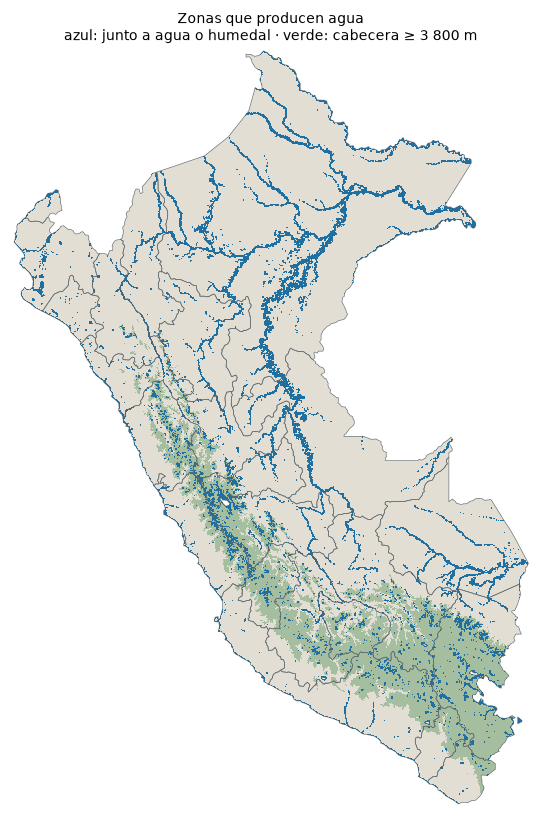

In [11]:
COLOR_CAT = {1: (31, 111, 160), 2: (166, 190, 160)}


def png_categoria(cat):
    rgba = np.zeros((*cat.shape, 4), dtype="uint8")
    for k, (r, g, b) in COLOR_CAT.items():
        rgba[cat == k] = (r, g, b, 200 if k == 1 else 150)
    rgba[cat == 0] = (226, 222, 212, 255)
    buf = io.BytesIO()
    plt.imsave(buf, rgba, format="png")
    plt.imsave(SALIDA / "zonas_agua.png", rgba)
    return base64.b64encode(buf.getvalue()).decode()


PNG_ZONAS = png_categoria(CATEGORIA)

fig, ax = plt.subplots(figsize=(5.5, 7.5))
ax.imshow(np.where(CATEGORIA == 255, np.nan, CATEGORIA), extent=[CAJA_PERU[0], CAJA_PERU[2],
          CAJA_PERU[1], CAJA_PERU[3]], cmap=matplotlib.colors.ListedColormap(["#E2DED4", "#1F6FA0", "#A6BEA0"]),
          interpolation="nearest")
departamentos.boundary.plot(ax=ax, color="#5B676D", linewidth=0.4)
ax.set_title("Zonas que producen agua\nazul: junto a agua o humedal · verde: cabecera ≥ 3 800 m", fontsize=9)
ax.axis("off")
plt.tight_layout()
plt.savefig(SALIDA / "mapa_zonas_agua.png", dpi=160)
plt.show()

## 4 · Raster → tabla: cada foco recibe su categoría

Con la grilla alineada no hace falta `zonal_stats`: la fila y la columna de cada foco salen
directamente de su latitud y longitud.

In [12]:
def categoria_de(df):
    fila = ((CAJA_PERU[3] - df.lat.values) / RES_CELDA).astype(int).clip(0, ny - 1)
    col = ((df.lon.values - CAJA_PERU[0]) / RES_CELDA).astype(int).clip(0, nx - 1)
    return df.assign(fila=fila, col=col, cat=CATEGORIA[fila, col])


historia = categoria_de(historia)
actual = categoria_de(actual)
historia = historia[historia.cat != 255]
actual = actual[actual.cat != 255]
for d in (historia, actual):
    d["zona_agua"] = d.cat.isin([1, 2])
    d["dia"] = d.fecha.dt.normalize()

print(f"{ANIO}: {actual.zona_agua.mean():.1%} de los focos cae en zonas que producen agua")
print(actual.cat.map(NOMBRES_CAT).value_counts().to_string())

2026: 24.2% de los focos cae en zonas que producen agua
cat
Resto del territorio      102470
Junto a agua o humedal     18941
Cabecera alta              13760


## 5 · Indicadores

Tres comparaciones:

1. **Por año:** qué porcentaje de los focos S-NPP del 1 de julio a la fecha de corte cayó en
   zonas de agua, de 2012 a 2026.
2. **Día a día:** los focos S-NPP en zonas de agua en 2026 frente a la mediana y el rango
   habitual (percentiles 10–90) de 2012–2025, con media móvil de 7 días.
3. **Por departamento:** focos totales, en zonas de agua, su porcentaje y la variación frente
   al promedio histórico.

In [13]:
snpp_actual = actual[actual.satelite == "S-NPP"]
comparable = pd.concat([historia, snpp_actual], ignore_index=True)

anual = (comparable.groupby("anio")
         .agg(focos=("zona_agua", "size"), zona=("zona_agua", "sum"),
              junto_agua=("cat", lambda s: (s == 1).sum()), cabecera=("cat", lambda s: (s == 2).sum()))
         .reset_index())
anual["pct_zona"] = 100 * anual.zona / anual.focos
hist = anual[anual.anio <= HISTORIA[1]]
fila_actual = anual[anual.anio == ANIO]
pct_actual = float(fila_actual.pct_zona.iloc[0]) if len(fila_actual) else np.nan
puesto_pct = int((hist.pct_zona > pct_actual).sum()) + 1
var_zona = 100 * (float(fila_actual.zona.iloc[0]) / hist.zona.mean() - 1) if len(fila_actual) else np.nan
print(f"{ANIO}: {pct_actual:.1f} % de focos S-NPP en zonas de agua (puesto {puesto_pct} de {len(hist) + 1}); "
      f"focos en zonas de agua {var_zona:+.0f} % frente al promedio")
anual

2026: 24.0 % de focos S-NPP en zonas de agua (puesto 2 de 15); focos en zonas de agua -6 % frente al promedio


,anio,focos,zona,junto_agua,cabecera,pct_zona
0,2012,63440,13943,11454,2489,22.0
1,2013,45387,10215,8244,1971,22.5
2,2014,41463,9265,7451,1814,22.3
3,2015,51968,11366,8922,2444,21.9
4,2016,58377,15033,10870,4163,25.8
5,2017,41479,9645,8365,1280,23.3
6,2018,45103,9618,7947,1671,21.3
7,2019,56062,13291,9382,3909,23.7
8,2020,65621,14989,9984,5005,22.8
9,2021,48960,9760,7948,1812,19.9


In [14]:
def serie_diaria(df, anio):
    inicio = pd.Timestamp(anio, *INICIO_TEMPORADA)
    dias = pd.date_range(inicio, pd.Timestamp(anio, CORTE.month, CORTE.day))
    s = df[df.zona_agua].groupby("dia").size().reindex(dias, fill_value=0)
    return s.rolling(7, min_periods=1).mean().values


anios_hist = sorted(historia.anio.unique())
hist_diaria = np.array([serie_diaria(historia[historia.anio == a], a) for a in anios_hist])
dias_temporada = pd.date_range(pd.Timestamp(ANIO, *INICIO_TEMPORADA), CORTE.normalize())
n = min(len(dias_temporada), hist_diaria.shape[1])
diario = {
    "fechas": [d.strftime("%Y-%m-%d") for d in dias_temporada[:n]],
    "actual": np.round(serie_diaria(snpp_actual, ANIO)[:n], 1).tolist(),
    "mediana": np.round(np.median(hist_diaria, axis=0)[:n], 1).tolist(),
    "p10": np.round(np.percentile(hist_diaria, 10, axis=0)[:n], 1).tolist(),
    "p90": np.round(np.percentile(hist_diaria, 90, axis=0)[:n], 1).tolist(),
}
sobre_rango = int(sum(a > p for a, p in zip(diario["actual"][-30:], diario["p90"][-30:])))
print(f"en los últimos 30 días, 2026 estuvo sobre el rango habitual {sobre_rango} días")

en los últimos 30 días, 2026 estuvo sobre el rango habitual 21 días


In [15]:
ult = CORTE.normalize()
d7 = actual[actual.dia > ult - pd.Timedelta(days=DIAS_MAPA)]
d30 = pd.date_range(ult - pd.Timedelta(days=29), ult)

prom_hist = (historia[historia.zona_agua].groupby(["departamento", "anio"]).size()
             .groupby("departamento").sum() / max(len(anios_hist), 1))
zona_snpp = snpp_actual[snpp_actual.zona_agua].groupby("departamento").size()

filas = []
for dep, g in actual.groupby("departamento"):
    serie = g[g.zona_agua].groupby("dia").size().reindex(d30, fill_value=0)
    base = prom_hist.get(dep, np.nan)
    filas.append({
        "departamento": dep.title(),
        "focos": len(g), "zona": int(g.zona_agua.sum()),
        "junto_agua": int((g.cat == 1).sum()), "cabecera": int((g.cat == 2).sum()),
        "pct_zona": 100 * g.zona_agua.mean(),
        "zona_7d": int(d7[(d7.departamento == dep) & d7.zona_agua].shape[0]),
        "vs_hist": 100 * (zona_snpp.get(dep, 0) / base - 1) if base and base > 0 else np.nan,
        "serie30": serie.tolist(),
    })
tabla_dep = pd.DataFrame(filas).sort_values("zona", ascending=False, ignore_index=True)
tabla_dep.drop(columns="serie30").head(12)

,departamento,focos,zona,junto_agua,cabecera,pct_zona,zona_7d,vs_hist
0,Puno,4674,4011,619,3392,85.8,102,110.3
1,Ucayali,23493,3843,3843,0,16.4,293,-24.7
2,Loreto,12476,3771,3771,0,30.2,271,-29.2
3,Cusco,7960,3747,1014,2733,47.1,130,26.0
4,Junin,13430,3114,1636,1478,23.2,153,-0.6
5,Huanuco,13219,2522,1654,868,19.1,213,-31.9
6,Ancash,4137,1801,360,1441,43.5,103,75.2
7,San Martin,17370,1760,1755,5,10.1,47,-43.5
8,Madre De Dios,7499,1571,1571,0,20.9,39,-37.2
9,Ayacucho,4031,1114,347,767,27.6,33,33.5


### Los incendios más grandes en zonas de agua

Un foco no es un incendio: un incendio son varios focos juntos. Agrupamos los focos de los
últimos 30 días que caen en celdas de ~1 km vecinas entre sí (una celda toca a otra si
comparten borde o esquina). Cada grupo es un incendio.

Para cada incendio calculamos:

| Columna | Qué es |
|---|---|
| Huella (ha) | Área de las celdas de 375 m con al menos un foco (~14 ha cada una). Sirve para comparar tamaños; no es el área quemada oficial |
| % en zonas de agua | Parte de sus focos junto a agua o humedal, o en cabecera alta |
| Distancia al agua | Del centro del incendio al cuerpo de agua o humedal más cercano (WorldCover) |
| Estado | «Activo» si tuvo focos en las últimas 24 horas |

Nos quedamos con los que tienen al menos 3 focos y al menos la mitad en zonas de agua.

Una diferencia con el monitor de la clase: ahí dos focos son del mismo incendio si están a
1 km **y a 48 horas** o menos. Aquí solo usamos la cercanía en el espacio, así que dos fuegos
en el mismo lugar con semanas de diferencia pueden quedar como uno solo.

In [16]:
VENTANA_INCENDIOS = 30
MIN_FOCOS = 3
PCT_MIN_ZONA = 50
TOP_INCENDIOS = 20
LADO_FOCO = 0.375 / 111                  # ~375 m en grados
HA_FOCO = 0.375 ** 2 * 100               # ~14 ha por celda de 375 m

if "distritos" not in globals():
    distritos = cargar_distritos()

rec = actual[actual.dia > CORTE.normalize() - pd.Timedelta(days=VENTANA_INCENDIOS)].copy()

# agrupar celdas vecinas (unión de conjuntos)
celdas_con_fuego = set(zip(rec.fila, rec.col))
padre = {c: c for c in celdas_con_fuego}


def raiz(c):
    while padre[c] != c:
        padre[c] = padre[padre[c]]
        c = padre[c]
    return c


for f, c in celdas_con_fuego:
    for df_ in (-1, 0, 1):
        for dc in (-1, 0, 1):
            vecina = (f + df_, c + dc)
            if vecina in padre:
                padre[raiz(vecina)] = raiz((f, c))
rec["incendio"] = [raiz(k) for k in zip(rec.fila, rec.col)]


def dist_agua_km(lat, lon, radio=50):
    f = int((CAJA_PERU[3] - lat) / RES_CELDA)
    c = int((lon - CAJA_PERU[0]) / RES_CELDA)
    f0, c0 = max(f - radio, 0), max(c - radio, 0)
    ys, xs = np.nonzero(agua[f0:f + radio + 1, c0:c + radio + 1])
    if not len(ys):
        return np.nan
    dy = (ys + f0 - f) * RES_CELDA * 111
    dx = (xs + c0 - c) * RES_CELDA * 111 * np.cos(np.radians(lat))
    return float(np.hypot(dx, dy).min())


grupos = []
for _, g in rec.groupby("incendio"):
    if len(g) < MIN_FOCOS or 100 * g.zona_agua.mean() < PCT_MIN_ZONA:
        continue
    huella = len(set(zip((g.lon / LADO_FOCO).round(), (g.lat / LADO_FOCO).round()))) * HA_FOCO
    grupos.append({"lon": g.lon.median(), "lat": g.lat.median(), "focos": len(g),
                   "inicio": g.fecha.min(), "fin": g.fecha.max(), "huella": huella,
                   "pct_zona": 100 * g.zona_agua.mean(), "pct_agua": 100 * (g.cat == 1).mean(),
                   "pct_cabecera": 100 * (g.cat == 2).mean(), "departamento": g.departamento.mode().iloc[0]})

incendios = pd.DataFrame(grupos)
if len(incendios):
    incendios = incendios.nlargest(TOP_INCENDIOS, "huella").reset_index(drop=True)
    puntos = gpd.GeoDataFrame(incendios, geometry=gpd.points_from_xy(incendios.lon, incendios.lat), crs="EPSG:4326")
    nombres = gpd.sjoin(puntos, distritos, how="left", predicate="within")
    nombres = nombres[~nombres.index.duplicated()]
    incendios["distrito"] = nombres.NOMBDIST.fillna("—").str.title().values
    incendios["provincia"] = nombres.NOMBPROV.fillna("—").str.title().values
    incendios["dist_agua_km"] = [dist_agua_km(a, o) for a, o in zip(incendios.lat, incendios.lon)]
    incendios["activo"] = incendios.fin >= CORTE - pd.Timedelta(hours=24)
    print(f"{len(rec):,} focos de los últimos {VENTANA_INCENDIOS} días → {len(set(rec.incendio)):,} grupos; "
          f"{len(grupos)} con ≥ {MIN_FOCOS} focos y ≥ {PCT_MIN_ZONA} % en zonas de agua")
    display(incendios[["distrito", "provincia", "departamento", "focos", "huella", "pct_zona",
                       "dist_agua_km", "activo"]].round(1))
else:
    print("no hay incendios que cumplan los criterios")

54,645 focos de los últimos 30 días → 8,395 grupos; 1065 con ≥ 3 focos y ≥ 50 % en zonas de agua


,distrito,provincia,departamento,focos,huella,pct_zona,dist_agua_km,activo
0,Sicuani,Canchis,CUSCO,239,"2,053.1",75.7,3.4,False
1,Alto Pichigua,Espinar,CUSCO,179,"1,462.5",100.0,7.4,False
2,El Tambo,Huancayo,JUNIN,125,"1,054.7",100.0,6.2,False
3,Santillana,Huanta,AYACUCHO,136,"1,040.6",56.6,6.6,False
4,Juliaca,San Roman,PUNO,93,998.4,100.0,3.3,False
5,Juli,Chucuito,PUNO,139,998.4,100.0,16.4,False
6,Capacmarca,Chumbivilcas,CUSCO,135,956.2,84.4,7.4,False
7,Cabanillas,San Roman,PUNO,91,928.1,100.0,10.8,False
8,Puno,Puno,PUNO,110,928.1,100.0,11.1,False
9,Urubamba,Urubamba,CUSCO,123,871.9,78.9,2.5,False


## 6 · Un incendio visto de cerca (el «mínimo» del trabajo)

**Qué incendio.** Si `CASO_DISTRITO` tiene un nombre, se usa el grupo de focos más grande de
los últimos 30 días en ese distrito. Si es `None`, el cuaderno elige el grupo más grande en
zonas que producen agua. Un "grupo" son los focos que caen en la misma celda de ~5 km.

**Qué imágenes.** Primero se listan todas las escenas candidatas con su fecha, el % de nubes
de la escena completa y el % de nubes **dentro de la zona del incendio** (calculado con la
banda `SCL`). Una escena puede tener 60 % de nubes en total y estar despejada justo sobre el
incendio, o al revés: por eso decide la nube en la zona. Se elige:

- **Antes:** la más reciente anterior al primer foco con menos de 20 % de nubes en la zona.
- **Después:** la más reciente posterior al último foco con menos de 20 % de nubes. Si el
  incendio sigue activo y no hay ninguna, la más reciente posterior al inicio.

**Qué se cuenta como quemado.** dNBR ≥ 0,27, sin nube ni sombra en ninguna de las dos
imágenes, y a menos de 1,5 km de algún foco, para no sumar cambios que no son de este fuego.

In [17]:
if "distritos" not in globals():
    distritos = cargar_distritos()


def elegir_caso(df, distrito=None):
    rec = df[df.dia > CORTE.normalize() - pd.Timedelta(days=CASO_DIAS)]
    if distrito:
        poli = distritos[distritos.NOMBDIST.str.upper() == distrito.upper()]
        if poli.empty:
            raise ValueError(f"no encontré el distrito {distrito} en peru-geojson")
        puntos = gpd.GeoSeries(gpd.points_from_xy(rec.lon, rec.lat), crs="EPSG:4326")
        rec = rec[puntos.within(poli.unary_union).values]
    else:
        rec = rec[rec.zona_agua]
    if rec.empty:
        return None
    # el incendio es el grupo de celdas vecinas de la tabla de incendios (no una celda fija de 5 km)
    rec = rec.assign(clave=[raiz(k) if k in padre else k for k in zip(rec.fila, rec.col)]) \
        if "padre" in globals() else rec.assign(clave=list(zip((rec.lon / 0.05).round(), (rec.lat / 0.05).round())))
    grupo = rec[rec.clave == rec.clave.value_counts().index[0]]
    centro = gpd.GeoDataFrame(geometry=gpd.points_from_xy([grupo.lon.median()], [grupo.lat.median()]), crs="EPSG:4326")
    dist = gpd.sjoin(centro, distritos, predicate="within")
    return {"lon": float(grupo.lon.median()), "lat": float(grupo.lat.median()),
            "inicio": grupo.dia.min(), "fin": grupo.dia.max(), "focos": grupo,
            "distrito": dist.NOMBDIST.iloc[0].title() if len(dist) else "—",
            "provincia": dist.NOMBPROV.iloc[0].title() if len(dist) else "—",
            "departamento": grupo.departamento.mode().iloc[0].title(),
            "categoria": NOMBRES_CAT[int(grupo.cat.mode().iloc[0])]}


caso = elegir_caso(actual, CASO_DISTRITO)
if caso is None:
    print("no hay focos recientes que cumplan el criterio: el dashboard omitirá el caso")
else:
    # la caja cubre todos los focos del incendio más 2 km de margen (y al menos ±CASO_KM del centro)
    d, m = CASO_KM / 111, 2 / 111
    f = caso["focos"]
    CAJA_CASO = (min(f.lon.min() - m, caso["lon"] - d), min(f.lat.min() - m, caso["lat"] - d),
                 max(f.lon.max() + m, caso["lon"] + d), max(f.lat.max() + m, caso["lat"] + d))
    CRS_CASO = f"EPSG:{32700 + int((caso['lon'] + 180) // 6) + 1}"
    print(f"incendio: {caso['distrito']} ({caso['provincia']}, {caso['departamento']}) — {caso['categoria']}")
    print(f"  {len(caso['focos'])} focos entre el {caso['inicio']:%d/%m} y el {caso['fin']:%d/%m} | "
          f"centro {caso['lat']:.4f}, {caso['lon']:.4f} | grilla en {CRS_CASO}")

incendio: Curahuasi (Abancay, Apurimac) — Junto a agua o humedal
  318 focos entre el 06/10 y el 19/10 | centro -13.6150, -72.4942 | grilla en EPSG:32718


In [18]:
SCL_NUBE = [0, 1, 3, 8, 9, 10]      # sin dato, saturado, sombra de nube, nube media, nube alta, cirros


def zona_incendio(geobox):
    """Píxeles a menos de 1,5 km de algún foco del caso."""
    focos = gpd.GeoSeries(gpd.points_from_xy(caso["focos"].lon, caso["focos"].lat), crs="EPSG:4326").to_crs(CRS_CASO)
    return geometry_mask([focos.buffer(1500).unary_union], out_shape=geobox.shape,
                         transform=geobox.affine, invert=True)


def candidatas(desde, hasta):
    items = buscar_sentinel2(CAJA_CASO, f"{desde:%Y-%m-%d}/{hasta:%Y-%m-%d}")
    if not items:
        return pd.DataFrame(columns=["fecha", "nubes_escena", "nubes_zona"]), []
    scl = cargar_bandas(items, CAJA_CASO, CRS_CASO, ["SCL"])["SCL"]
    dentro = zona_incendio(scl.odc.geobox)
    filas = []
    for t in scl.time.values:
        capa = np.asarray(scl.sel(time=t).values)
        dia = pd.Timestamp(t).normalize()
        escena = [i.properties.get("eo:cloud_cover", np.nan) for i in items
                  if pd.Timestamp(i.datetime).tz_localize(None).normalize() == dia]
        filas.append({"fecha": dia, "nubes_escena": float(np.nanmean(escena)) if escena else np.nan,
                      "nubes_zona": 100 * np.isin(capa[dentro], SCL_NUBE).mean()})
    return pd.DataFrame(filas).sort_values("fecha", ignore_index=True), items


if caso is not None:
    antes_fin = caso["inicio"] - pd.Timedelta(days=1)
    cand_antes, items_antes = candidatas(antes_fin - pd.Timedelta(days=VENTANA_ANTES), antes_fin)
    cand_despues, items_despues = candidatas(caso["inicio"] + pd.Timedelta(days=2), CORTE)

    print("CANDIDATAS «ANTES» (nubes en %):")
    print(cand_antes.to_string(index=False, formatters={"fecha": "{:%d/%m/%Y}".format}) if len(cand_antes) else "  ninguna")
    print("\nCANDIDATAS «DESPUÉS»:")
    print(cand_despues.to_string(index=False, formatters={"fecha": "{:%d/%m/%Y}".format}) if len(cand_despues) else "  ninguna")

    def elegir(cand, preferir_despues_de=None):
        """La más reciente limpia; si no hay, la menos nublada tolerable (y se marca como parcial)."""
        limpias = cand[cand.nubes_zona <= NUBES_MAX_ZONA]
        if preferir_despues_de is not None and len(limpias[limpias.fecha > preferir_despues_de]):
            return limpias[limpias.fecha > preferir_despues_de].iloc[-1], False
        if len(limpias):
            return limpias.iloc[-1], False
        tolerables = cand[cand.nubes_zona <= NUBES_TOLERABLE]
        if len(tolerables):
            return tolerables.sort_values("nubes_zona").iloc[0], True
        return None, False

    ELEGIDA_ANTES, parcial_a = elegir(cand_antes)
    ELEGIDA_DESPUES, parcial_d = elegir(cand_despues, preferir_despues_de=caso["fin"])
    PARCIAL = parcial_a or parcial_d
    post_fin = cand_despues[(cand_despues.fecha > caso["fin"]) & (cand_despues.nubes_zona <= NUBES_TOLERABLE)]

    print()
    for nombre, e in [("antes", ELEGIDA_ANTES), ("después", ELEGIDA_DESPUES)]:
        print(f"imagen {nombre}: " + (f"{e.fecha:%d/%m/%Y} — {e.nubes_zona:.1f} % de nubes en la zona "
                                      f"({e.nubes_escena:.0f} % en la escena completa)" if e is not None
                                      else f"no hay ninguna con ≤ {NUBES_MAX_ZONA} % de nubes en la zona"))
    if PARCIAL:
        print(f"  ⚠ no hubo imagen con ≤ {NUBES_MAX_ZONA} % de nubes: se usa la menos nublada. Las nubes se "
              "enmascaran, así que el área quemada es un MÍNIMO (lo que estaba bajo nubes no se cuenta).")
    if ELEGIDA_DESPUES is not None and ELEGIDA_DESPUES.fecha <= caso["fin"]:
        print("  (la imagen «después» es anterior al último foco: el incendio seguía activo y el área puede ser mayor)")
    if ELEGIDA_DESPUES is None:
        print("  → no hay imagen «después» usable. Opciones: esperar el próximo paso de Sentinel-2 (cada ~5 días), "
              "subir NUBES_TOLERABLE o elegir un incendio más antiguo con CASO_DISTRITO.")

CANDIDATAS «ANTES» (nubes en %):
     fecha  nubes_escena  nubes_zona
06/08/2026           3.6         8.3
08/08/2026           4.6        23.7
09/08/2026          23.5         7.9
14/08/2026          30.4        30.5
16/08/2026          58.8        91.6
19/08/2026          21.4        37.4
21/08/2026          34.3        20.4
24/08/2026          70.1        47.0
26/08/2026           0.1         0.0
28/08/2026          55.0        32.2
29/08/2026          34.5        64.0
31/08/2026          17.5         0.6
03/09/2026          41.7        73.0
05/09/2026          60.6        51.6
10/09/2026          47.7        54.0
13/09/2026          52.2        19.5
15/09/2026          24.0         4.1
17/09/2026          75.8        16.6
20/09/2026           6.1         0.0
23/09/2026          30.9        25.4
25/09/2026          10.3         8.4
28/09/2026          69.6        73.3
30/09/2026          34.1        13.7
03/10/2026          12.8         0.0
05/10/2026          14.9         4.8

CAND

**Antes de seguir, miren las dos tablas.** ¿Las fechas tienen sentido respecto al inicio del
incendio? ¿La nube en la zona es realmente baja? Si no hay imagen limpia, amplíen
`VENTANA_ANTES` o suban `NUBES_MAX_ZONA` y díganlo en el README.

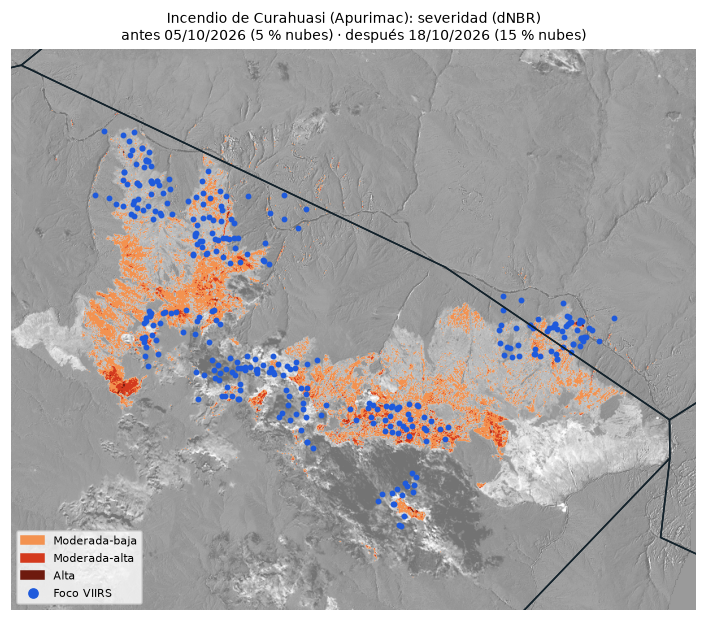

área quemada: 1,115.5 ha (de ellas 2.1 ha en agua o humedal)
Moderada-baja   1,001.2
Moderada-alta     110.5
Alta                3.9


,distrito,provincia,Moderada-baja,Moderada-alta,Alta,total
0,Curahuasi,Abancay,984.2,108.2,2.8,"1,095.2"
1,Limatambo,Anta,16.9,2.2,1.1,20.2


In [19]:
SEVERIDAD = [(0.27, 0.44, "Moderada-baja", (243, 146, 80)),
             (0.44, 0.66, "Moderada-alta", (212, 58, 30)),
             (0.66, 9.00, "Alta", (110, 26, 14))]
HA_PIXEL = 20 * 20 / 10_000


def imagen_del_dia(items, fecha):
    del_dia = [i for i in items if pd.Timestamp(i.datetime).tz_localize(None).normalize() == fecha]
    return cargar_bandas(del_dia, CAJA_CASO, CRS_CASO, ["B04", "B08", "B12", "SCL"]).isel(time=0)


def reflectancia(ds, banda):
    return ((np.asarray(ds[banda].values, dtype="float32") - 1000).clip(min=0)) / 10_000   # desfase +1000


def falso_color(ds):
    rgb = np.dstack([reflectancia(ds, b) for b in ("B12", "B08", "B04")])
    lo, hi = np.nanpercentile(rgb, 2), np.nanpercentile(rgb, 98)
    return (np.clip((rgb - lo) / (hi - lo + 1e-6), 0, 1) * 255).astype("uint8")


def png64(arr, nombre):
    plt.imsave(SALIDA / f"{nombre}.png", arr)
    buf = io.BytesIO()
    plt.imsave(buf, arr, format="png")
    return base64.b64encode(buf.getvalue()).decode()


CASO = None
if caso is not None and ELEGIDA_ANTES is not None and ELEGIDA_DESPUES is not None:
    ds_a = imagen_del_dia(items_antes, ELEGIDA_ANTES.fecha)
    ds_d = imagen_del_dia(items_despues, ELEGIDA_DESPUES.fecha)
    nbr = {}
    for k, ds in (("a", ds_a), ("d", ds_d)):
        nir, swir = reflectancia(ds, "B08"), reflectancia(ds, "B12")
        nbr[k] = np.where(nir + swir > 0, (nir - swir) / (nir + swir + 1e-9), np.nan)
    dnbr = nbr["a"] - nbr["d"]
    gb = ds_a.odc.geobox
    limpio = ~np.isin(np.asarray(ds_a.SCL.values), SCL_NUBE + [6]) & ~np.isin(np.asarray(ds_d.SCL.values), SCL_NUBE + [6])
    dentro = zona_incendio(gb)
    quemado = dentro & limpio & np.isfinite(dnbr) & (dnbr >= UMBRAL_DNBR)
    cob = np.asarray(cargar_worldcover(gb, resampling="nearest").values)

    clases = np.zeros(dnbr.shape, dtype="uint8")
    for k, (lo, hi, _, _) in enumerate(SEVERIDAD, start=1):
        clases[quemado & (dnbr >= lo) & (dnbr < hi)] = k

    # hectáreas por distrito y severidad
    dist_caso = distritos.cx[CAJA_CASO[0]:CAJA_CASO[2], CAJA_CASO[1]:CAJA_CASO[3]].to_crs(CRS_CASO)
    por_distrito = []
    for _, dd in dist_caso.iterrows():
        m = geometry_mask([dd.geometry], out_shape=gb.shape, transform=gb.affine, invert=True)
        fila = {"distrito": dd.NOMBDIST.title(), "provincia": dd.NOMBPROV.title()}
        for k, (_, _, nombre, _) in enumerate(SEVERIDAD, start=1):
            fila[nombre] = round(float((m & (clases == k)).sum() * HA_PIXEL), 1)
        fila["total"] = round(sum(fila[n] for _, _, n, _ in SEVERIDAD), 1)
        if fila["total"] > 0:
            por_distrito.append(fila)
    tabla_caso = pd.DataFrame(por_distrito)

    # mapa de severidad (para el README y los slides)
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    fondo = np.clip((np.nan_to_num(dnbr) + 0.2) / 0.9, 0, 1)
    ax.imshow(fondo, cmap="Greys_r", extent=[gb.boundingbox.left, gb.boundingbox.right,
              gb.boundingbox.bottom, gb.boundingbox.top], alpha=0.55)
    color = np.zeros((*clases.shape, 4))
    for k, (_, _, _, rgb) in enumerate(SEVERIDAD, start=1):
        color[clases == k] = (*(np.array(rgb) / 255), 1)
    ax.imshow(color, extent=[gb.boundingbox.left, gb.boundingbox.right, gb.boundingbox.bottom, gb.boundingbox.top])
    dist_caso.boundary.plot(ax=ax, color="#13222B", linewidth=1)
    for _, dd in dist_caso.iterrows():
        c = dd.geometry.representative_point()
        if gb.boundingbox.left < c.x < gb.boundingbox.right and gb.boundingbox.bottom < c.y < gb.boundingbox.top:
            ax.annotate(dd.NOMBDIST.title(), (c.x, c.y), fontsize=8, ha="center", color="#13222B")
    gpd.GeoSeries(gpd.points_from_xy(caso["focos"].lon, caso["focos"].lat), crs="EPSG:4326").to_crs(CRS_CASO) \
        .plot(ax=ax, color="#1E5ADC", markersize=8)
    ax.set_xlim(gb.boundingbox.left, gb.boundingbox.right)
    ax.set_ylim(gb.boundingbox.bottom, gb.boundingbox.top)
    ax.set_title(f"Incendio de {caso['distrito']} ({caso['departamento']}): severidad (dNBR)\n"
                 f"antes {ELEGIDA_ANTES.fecha:%d/%m/%Y} ({ELEGIDA_ANTES.nubes_zona:.0f} % nubes) · "
                 f"después {ELEGIDA_DESPUES.fecha:%d/%m/%Y} ({ELEGIDA_DESPUES.nubes_zona:.0f} % nubes)", fontsize=9)
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=np.array(c) / 255) for *_, c in SEVERIDAD] +
              [plt.Line2D([], [], marker="o", ls="", color="#1E5ADC")],
              labels=[n for _, _, n, _ in SEVERIDAD] + ["Foco VIIRS"], fontsize=7.5, loc="lower left")
    ax.axis("off")
    plt.tight_layout()
    plt.savefig(SALIDA / "mapa_caso.png", dpi=170)
    plt.show()

    # imagen de severidad para el dashboard
    img = np.dstack([fondo * 205 + 40] * 3).astype("uint8")
    for k, (_, _, _, rgb) in enumerate(SEVERIDAD, start=1):
        img[clases == k] = rgb
    img[np.isin(cob, CLASES_AGUA) & ~quemado] = (90, 150, 200)

    CASO = {
        "distrito": caso["distrito"], "provincia": caso["provincia"], "lugar": caso["departamento"],
        "categoria": caso["categoria"], "lon": round(caso["lon"], 4), "lat": round(caso["lat"], 4),
        "inicio": f"{caso['inicio']:%d/%m}", "fin": f"{caso['fin']:%d/%m}", "focos": int(len(caso["focos"])),
        "fecha_antes": f"{ELEGIDA_ANTES.fecha:%d/%m/%Y}", "nubes_antes": round(float(ELEGIDA_ANTES.nubes_zona), 1),
        "fecha_despues": f"{ELEGIDA_DESPUES.fecha:%d/%m/%Y}", "nubes_despues": round(float(ELEGIDA_DESPUES.nubes_zona), 1),
        "activo": bool(ELEGIDA_DESPUES.fecha <= caso["fin"]),
        "parcial": bool(PARCIAL),
        "pct_sin_dato": round(float(100 * (dentro & ~limpio).sum() / max(dentro.sum(), 1)), 1),
        "ha_quemada": round(float(quemado.sum() * HA_PIXEL), 1),
        "ha_agua": round(float((quemado & np.isin(cob, CLASES_AGUA)).sum() * HA_PIXEL), 1),
        "severidad": {n: round(float((clases == k).sum() * HA_PIXEL), 1) for k, (_, _, n, _) in enumerate(SEVERIDAD, start=1)},
        "por_distrito": por_distrito,
        "img_antes": png64(falso_color(ds_a), "caso_antes"),
        "img_despues": png64(falso_color(ds_d), "caso_despues"),
        "img_dnbr": png64(img, "caso_dnbr"),
    }
    print(f"área quemada: {CASO['ha_quemada']:,.1f} ha (de ellas {CASO['ha_agua']:,.1f} ha en agua o humedal)")
    print(pd.Series(CASO["severidad"]).to_string())
    display(tabla_caso)
elif caso is not None:
    CASO = {"distrito": caso["distrito"], "provincia": caso["provincia"], "lugar": caso["departamento"],
            "categoria": caso["categoria"], "lon": round(caso["lon"], 4), "lat": round(caso["lat"], 4),
            "inicio": f"{caso['inicio']:%d/%m}", "fin": f"{caso['fin']:%d/%m}", "focos": int(len(caso["focos"])),
            "error": (f"no hubo imágenes con ≤ {NUBES_TOLERABLE} % de nubes en la zona "
                      + ("antes" if ELEGIDA_ANTES is None else "después") + " del incendio")}
    print(CASO["error"])

## 7 · El dashboard

Un solo archivo, `salidas_agua/dashboard_fuego_agua.html` (y una copia en `docs/index.html` para GitHub Pages). **No usa librerías ni mapas de
internet:** el mapa y los gráficos se dibujan con SVG dentro del archivo, así que se abre igual
con o sin conexión. Las únicas cosas externas son las fuentes tipográficas de Google, y si no
cargan se usa la del sistema.

In [20]:
def r(v, d=1):
    return None if v is None or (isinstance(v, float) and not np.isfinite(v)) else round(float(v), d)


celdas7 = (d7.assign(lon_c=CAJA_PERU[0] + (d7.col + 0.5) * RES_CELDA,
                     lat_c=CAJA_PERU[3] - (d7.fila + 0.5) * RES_CELDA,
                     d=(d7.dia - (ult - pd.Timedelta(days=DIAS_MAPA - 1))).dt.days)
           .groupby(["d", "lon_c", "lat_c", "cat"]).size().reset_index(name="n"))
dias7 = [ult - pd.Timedelta(days=DIAS_MAPA - 1 - i) for i in range(DIAS_MAPA)]
por_dia = [{"fecha": f"{dd:%Y-%m-%d}", "total": int((d7.dia == dd).sum()),
            "zona": int(((d7.dia == dd) & d7.zona_agua).sum())} for dd in dias7]

serie_nac = actual[actual.zona_agua].groupby("dia").size().reindex(d30, fill_value=0)
total_24 = actual[actual.fecha > CORTE - pd.Timedelta(hours=24)]
previas_24 = actual[(actual.fecha <= CORTE - pd.Timedelta(hours=24)) & (actual.fecha > CORTE - pd.Timedelta(hours=48))]
top7 = tabla_dep.sort_values("zona_7d", ascending=False).iloc[0] if len(tabla_dep) else None

geo_dep = json.loads(departamentos.assign(geometry=departamentos.geometry.simplify(0.02))
                     .assign(nombre=lambda d: d.NOMBDEP.str.title())[["nombre", "geometry"]].to_json())
for f in geo_dep["features"]:            # menos decimales = archivo más liviano
    def redondear(c):
        return [round(c[0], 3), round(c[1], 3)] if isinstance(c[0], (int, float)) else [redondear(x) for x in c]
    f["geometry"]["coordinates"] = redondear(f["geometry"]["coordinates"])

DATOS = {
    "meta": {"corte": CORTE.strftime("%Y-%m-%dT%H:%M"), "anio": ANIO, "historia": f"{HISTORIA[0]}–{HISTORIA[1]}",
             "altitud": ALTITUD_CABECERA, "caja": CAJA_PERU, "generado": datetime.now().strftime("%d/%m/%Y %H:%M"),
             "ultimo_inpe": ultimo_inpe.strftime("%d/%m %H:%M") if len(inpe) else None},
    "kpi": {
        "focos": int(len(actual)), "zona": int(actual.zona_agua.sum()),
        "pct_zona": r(100 * actual.zona_agua.mean()),
        "junto_agua": int((actual.cat == 1).sum()), "cabecera": int((actual.cat == 2).sum()),
        "zona_24h": int(total_24.zona_agua.sum()), "zona_24h_previas": int(previas_24.zona_agua.sum()),
        "serie30": serie_nac.tolist(),
        "pct_snpp": r(pct_actual), "puesto_pct": puesto_pct, "n_anios": int(len(hist) + 1),
        "var_zona": r(var_zona, 0), "sobre_rango": sobre_rango,
        "humedal_7d": int((d7.cat == 1).sum()),
        "top_dep": top7.departamento if top7 is not None else None,
        "top_dep_n": int(top7.zona_7d) if top7 is not None else 0,
    },
    "anual": [{"anio": int(a.anio), "focos": int(a.focos), "zona": int(a.zona), "pct": r(a.pct_zona)}
              for a in anual.itertuples()],
    "diario": diario,
    "deps": [{k: (r(v) if isinstance(v, float) else v) for k, v in f.items()} for f in tabla_dep.to_dict("records")],
    "mapa": {"dias": por_dia, "celdas": celdas7[["d", "lon_c", "lat_c", "cat", "n"]].round(3).values.tolist(),
             "deps": geo_dep},
    "caso": CASO,
    "incendios": [{"distrito": i.distrito, "provincia": i.provincia, "departamento": i.departamento.title(),
                   "lon": r(i.lon, 4), "lat": r(i.lat, 4), "focos": int(i.focos), "huella": r(i.huella, 0),
                   "inicio": f"{i.inicio:%Y-%m-%d}", "fin": f"{i.fin:%Y-%m-%d}", "pct_zona": r(i.pct_zona, 0),
                   "pct_agua": r(i.pct_agua, 0), "pct_cabecera": r(i.pct_cabecera, 0),
                   "dist_agua_km": r(i.dist_agua_km, 1), "activo": bool(i.activo)}
                  for i in incendios.itertuples()] if len(incendios) else [],
}
print(f"datos listos: {len(json.dumps(DATOS)) / 1e6:.2f} MB")

datos listos: 4.95 MB


In [ ]:
# Plantilla del dashboard (HTML, CSS y JavaScript sin librerías externas).
PLANTILLA = r'''<!doctype html>
<html lang="es">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>El fuego y el agua · Perú</title>
<link rel="preconnect" href="https://fonts.googleapis.com">
<link href="https://fonts.googleapis.com/css2?family=Barlow+Condensed:wght@600;700&family=IBM+Plex+Sans:wght@400;500;600&display=swap" rel="stylesheet">
<style>
:root{--fondo:#EEF2F3;--hoja:#FFFFFF;--tinta:#13222B;--suave:#5A6871;--linea:#D5DDE0;--pista:#E3E9EB;
--agua:#1F6FA0;--cabecera:#7E9C76;--fuego:#C8351B;--ambar:#E8923A;--gris:#9AA3A8;--gris-claro:#C4CACD;
--barra:#13222B;--barra-txt:#E9EEF0;color-scheme:light}
@media (prefers-color-scheme:dark){:root{--fondo:#0E181E;--hoja:#15232B;--tinta:#E3EAED;--suave:#9DAAB1;
--linea:#2A3A42;--pista:#22323A;--agua:#5FA8D6;--cabecera:#9DB894;--fuego:#EE5B3B;--ambar:#F0A55A;
--gris:#7C878D;--gris-claro:#4A575D;--barra:#0A1216;--barra-txt:#E3EAED;color-scheme:dark}}
*{box-sizing:border-box}
html{scroll-behavior:smooth;scroll-padding-top:64px}
body{margin:0;background:var(--fondo);color:var(--tinta);font:16px/1.55 "IBM Plex Sans","Segoe UI",Roboto,Arial,sans-serif}
h1,h2,h3,.num{font-family:"Barlow Condensed","Arial Narrow",Arial,sans-serif;font-weight:700}
nav.barra{position:sticky;top:0;z-index:10;background:var(--barra);color:var(--barra-txt);display:flex;align-items:center;
gap:22px;padding:12px 24px;overflow-x:auto;white-space:nowrap}
nav.barra b{font-family:"Barlow Condensed",Arial,sans-serif;font-size:1.25rem;letter-spacing:.2px}
nav.barra a{color:var(--barra-txt);opacity:.78;text-decoration:none;font-size:.95rem}
nav.barra a:hover,nav.barra a:focus-visible{opacity:1;text-decoration:underline}
nav.barra .corte{margin-left:auto;font-size:.9rem;opacity:.85}
main{max-width:1240px;margin:0 auto;padding:36px 24px 72px}
section{margin-top:56px}
.cabeza{display:grid;grid-template-columns:minmax(0,1fr) minmax(0,1fr);gap:24px 48px;align-items:end;margin-bottom:18px}
.cabeza h2{font-size:2rem;line-height:1.08;margin:0}
.cabeza p{margin:0;color:var(--suave)}
h1{font-size:clamp(2.2rem,5.2vw,3.9rem);line-height:1.02;margin:0 0 18px;max-width:20ch}
.lead{font-size:1.2rem;max-width:68ch;margin:0}
.meta{color:var(--suave);font-size:.92rem;margin-top:16px;display:flex;flex-wrap:wrap;gap:6px 26px}
.aviso{margin-top:18px;max-width:72ch;padding:12px 16px;border:1px solid #D9B25C;background:#FBF3E1;color:#4A3812;border-radius:6px}
@media (prefers-color-scheme:dark){.aviso{background:#33290F;color:#F1E1B4;border-color:#7A6020}}
.kpis{display:grid;grid-template-columns:repeat(3,minmax(0,1fr));background:var(--hoja);border:1px solid var(--linea);border-radius:8px;margin-top:30px}
.kpi{padding:20px 22px;border-right:1px solid var(--linea);border-bottom:1px solid var(--linea);display:flex;flex-direction:column;gap:6px}
.kpi:nth-child(3n){border-right:none}.kpi:nth-last-child(-n+3){border-bottom:none}
.kpi .tit{font-size:.9rem;color:var(--suave);font-weight:500}
.kpi .num{font-size:2.9rem;line-height:1}
.kpi .nota{font-size:.92rem;color:var(--suave)}
.kpi svg{width:100%;height:48px;display:block}
.fuego{color:var(--fuego)}.aguac{color:var(--agua)}
.panel{background:var(--hoja);border:1px solid var(--linea);border-radius:8px;padding:20px}
.mapa-wrap{display:grid;grid-template-columns:minmax(0,1.1fr) minmax(0,1fr);gap:24px}
#mapa{width:100%;height:auto;display:block;background:var(--pista);border-radius:6px}
#mapa .dep{fill:none;stroke:var(--tinta);stroke-opacity:.45;stroke-width:.6}
#mapa .dep.sel{stroke-opacity:1;stroke-width:2.2}
.controles{display:flex;flex-wrap:wrap;gap:10px;align-items:center}
button.b{font:inherit;cursor:pointer;border:1px solid var(--tinta);background:var(--hoja);color:var(--tinta);padding:7px 14px;border-radius:4px}
button.b.prim{background:var(--tinta);color:var(--hoja)}
input[type=range]{width:100%;accent-color:var(--fuego)}
label.chk{display:flex;gap:8px;align-items:center;font-size:.95rem}
.dia{font-family:"Barlow Condensed",Arial,sans-serif;font-size:1.9rem;font-weight:700;margin:14px 0 2px}
.leyenda{display:flex;flex-wrap:wrap;gap:6px 18px;font-size:.88rem;color:var(--suave);margin-top:12px}
.leyenda i{display:inline-block;width:11px;height:11px;margin-right:6px;vertical-align:-1px;border-radius:2px}
.dos{display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:24px}
.panel h3{font-size:1.35rem;margin:0 0 4px}
.panel .sub{color:var(--suave);font-size:.92rem;margin:0 0 10px}
svg text{font-family:"IBM Plex Sans",Arial,sans-serif;font-size:11px;fill:var(--suave)}
svg .eje{stroke:var(--linea)}
.tabla{overflow-x:auto;background:var(--hoja);border:1px solid var(--linea);border-radius:8px}
table{border-collapse:collapse;width:100%;font-size:.94rem;min-width:900px}
th,td{padding:10px 12px;border-bottom:1px solid var(--linea);text-align:right;white-space:nowrap}
th:first-child,td:first-child{text-align:left}
th button{all:unset;cursor:pointer;color:var(--suave);font-weight:600}
th button:focus-visible{outline:2px solid var(--agua);outline-offset:2px}
th button[aria-sort]::after{content:" ↓"}th button[aria-sort=ascending]::after{content:" ↑"}
tbody tr{cursor:pointer}tbody tr:hover{background:var(--pista)}
tbody tr.sel{background:var(--pista);box-shadow:inset 3px 0 0 var(--tinta)}
select{font:inherit;color:var(--tinta);background:var(--hoja);border:1px solid var(--tinta);border-radius:4px;padding:7px 10px}
.lugar small{display:block;color:var(--suave);font-size:.84rem}
.barra-h{display:inline-block;height:12px;border-radius:2px;vertical-align:middle;margin-right:8px}
.estado{display:inline-flex;align-items:center;gap:6px}.estado i{width:9px;height:9px;border-radius:50%;display:inline-block}
.apilada{display:inline-flex;width:110px;height:12px;border-radius:2px;overflow:hidden;background:var(--pista);vertical-align:middle;margin-right:8px}
#tabla-inc td,#tabla-inc th{text-align:left}#tabla-inc td.n,#tabla-inc th:last-child{text-align:right}
@keyframes latido{0%{r:6;opacity:1}100%{r:22;opacity:0}}
#mapa .marca-onda{animation:latido 1.6s ease-out infinite}
@media (prefers-reduced-motion:reduce){#mapa .marca-onda{animation:none}}
.chip{display:inline-block;min-width:62px;padding:2px 8px;border-radius:4px;font-weight:600;text-align:center}
.mini-barra{display:inline-block;height:9px;border-radius:5px;background:var(--fuego);vertical-align:middle;margin-left:8px}
.comparar{position:relative;overflow:hidden;border-radius:6px;aspect-ratio:1/1;background:var(--pista)}
.comparar img{position:absolute;inset:0;width:100%;height:100%;object-fit:cover;image-rendering:pixelated}
.comparar .arriba{clip-path:inset(0 50% 0 0)}
.etq{position:absolute;top:10px;padding:2px 8px;font-size:.8rem;background:rgba(0,0,0,.65);color:#fff;border-radius:3px}
.cifras{display:grid;grid-template-columns:repeat(3,minmax(0,1fr));gap:1px;background:var(--linea);border:1px solid var(--linea);border-radius:6px;overflow:hidden;margin-top:16px}
.cifras div{background:var(--hoja);padding:12px 14px}.cifras span{display:block;color:var(--suave);font-size:.86rem}
.cifras b{font-family:"Barlow Condensed",Arial,sans-serif;font-size:1.7rem}
details.metodo{background:var(--hoja);border:1px solid var(--linea);border-radius:8px;padding:18px 22px}
details.metodo summary{cursor:pointer;font-family:"Barlow Condensed",Arial,sans-serif;font-size:1.4rem;font-weight:700}
.metodo .cols{display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:12px 40px;margin-top:10px}
.metodo h4{margin:14px 0 4px}.metodo p{margin:0 0 10px;max-width:70ch}
:focus-visible{outline:2px solid var(--agua);outline-offset:2px}
footer{margin-top:40px;color:var(--suave);font-size:.88rem}
@media (max-width:900px){.cabeza,.mapa-wrap,.dos,.metodo .cols{grid-template-columns:1fr}
.kpis{grid-template-columns:1fr 1fr}.kpi:nth-child(3n){border-right:1px solid var(--linea)}.kpi:nth-child(2n){border-right:none}
.kpi:nth-last-child(-n+3){border-bottom:1px solid var(--linea)}.kpi:nth-last-child(-n+2){border-bottom:none}}
@media (max-width:560px){.kpis{grid-template-columns:1fr}.kpi{border-right:none!important;border-bottom:1px solid var(--linea)!important}
.cifras{grid-template-columns:1fr 1fr}}
</style>
</head>
<body>
<nav class="barra" aria-label="Secciones">
<b>El fuego y el agua</b>
<a href="#resumen">Resumen</a><a href="#mapa-sec">Mapa</a><a href="#temporada">Temporada</a>
<a href="#departamentos">Departamentos</a><a href="#incendios">Incendios</a><a href="#caso">Un incendio de cerca</a><a href="#metodo">Fuentes y método</a>
<span class="corte" id="corte"></span>
</nav>
<main>
<section id="resumen" style="margin-top:8px">
<h1 id="titular"></h1>
<p class="lead" id="lead"></p>
<div class="meta" id="meta"></div>
<div class="aviso" id="aviso" hidden></div>
<div class="kpis" id="kpis"></div>
</section>

<section id="mapa-sec">
<div class="cabeza"><h2>La semana en el mapa</h2>
<p>Cada cuadrito es una celda de ~1 km con focos de calor ese día. En azul, las zonas junto a agua o humedales; en verde, las cabeceras sobre <span id="alt"></span> m.</p></div>
<div class="mapa-wrap">
<div class="panel"><svg id="mapa" role="img" aria-label="Mapa del Perú con focos de calor y zonas que producen agua"></svg>
<div class="leyenda"><span><i style="background:var(--fuego)"></i>Foco junto a agua o humedal</span>
<span><i style="background:var(--ambar)"></i>Foco en cabecera alta</span><span><i style="background:var(--gris)"></i>Otro foco</span>
<span><i style="background:var(--tinta);opacity:.3"></i>Días anteriores</span>
<span><i style="background:var(--agua)"></i>Zona junto a agua</span><span><i style="background:var(--cabecera)"></i>Cabecera alta</span></div></div>
<div class="panel">
<div class="controles"><button class="b prim" id="play" type="button">Reproducir la semana</button>
<label class="chk"><input type="checkbox" id="anteriores" checked> Mostrar días anteriores en gris</label>
<label class="chk"><input type="checkbox" id="capa" checked> Capa de zonas de agua</label></div>
<p class="dia" id="dia-tit"></p><p class="sub" id="dia-sub" style="margin:0 0 14px"></p>
<label for="slider" class="sub">Día</label><input type="range" id="slider" min="0" max="6" step="1">
<svg id="barras7" style="width:100%;height:200px;margin-top:18px" role="img" aria-label="Focos por día"></svg>
<p class="sub" style="margin-top:6px">Barras: focos por día en el Perú; la parte de color es la que cae en zonas que producen agua. Toque una barra para ir a ese día.</p>
</div></div>
</section>

<section id="temporada">
<div class="cabeza"><h2>La temporada frente a <span class="hist"></span></h2>
<p>Para comparar años se usa un solo satélite (S-NPP), que observa el Perú con el mismo instrumento desde 2012.</p></div>
<div class="dos">
<div class="panel"><h3 id="t1"></h3><p class="sub">Focos S-NPP en zonas que producen agua, por día, media móvil de 7 días.</p>
<svg id="g-diario" style="width:100%;height:300px" role="img" aria-label="Serie diaria frente al rango habitual"></svg>
<div class="leyenda"><span><i style="background:var(--fuego)"></i><span class="anio"></span></span>
<span><i style="background:var(--suave)"></i>Mediana <span class="hist"></span></span>
<span><i style="background:var(--pista);border:1px solid var(--linea)"></i>Rango habitual (percentiles 10–90)</span></div></div>
<div class="panel"><h3 id="t2"></h3><p class="sub">% de los focos S-NPP del 1 de julio a la fecha de corte que cayó en zonas que producen agua.</p>
<svg id="g-anual" style="width:100%;height:300px" role="img" aria-label="Porcentaje por año"></svg></div>
</div>
</section>

<section id="departamentos">
<div class="cabeza"><h2>Departamentos</h2>
<p>Focos de los tres satélites VIIRS desde el 1 de julio. La comparación histórica usa S-NPP. Ordene con los encabezados; seleccione un departamento para verlo en el mapa.</p></div>
<div class="tabla"><table id="tabla"></table></div>
</section>

<section id="incendios">
<div class="cabeza"><h2>Los incendios más grandes en zonas de agua</h2>
<p>Focos de los últimos 30 días agrupados en incendios (celdas de ~1 km vecinas), con al menos 3 focos y la mitad o más en zonas que producen agua. Seleccione una fila para ubicarlo en el mapa.</p></div>
<div class="controles" style="margin-bottom:14px"><label for="orden-inc">Ordenar por</label>
<select id="orden-inc"><option value="huella">Huella (ha)</option><option value="pct_zona">% en zonas de agua</option>
<option value="dist_agua_km">Cercanía al agua</option><option value="fin">Más reciente</option><option value="focos">Focos</option></select>
<span class="sub" style="margin:0">Huella: área de las celdas de 375 m con al menos un foco. Sirve para comparar; no es el área quemada oficial.</span></div>
<div class="tabla"><table id="tabla-inc"></table></div>
</section>

<section id="caso">
<div class="cabeza"><h2>Un incendio en una zona de agua, de cerca</h2>
<p id="caso-intro"></p></div>
<div id="caso-cuerpo"></div>
</section>

<section id="metodo">
<details class="metodo" open><summary>Metodología, fuentes y limitaciones</summary>
<div class="cols">
<div><h4>Focos de calor</h4>
<p>Un foco es un píxel de 375 m en el que un sensor VIIRS registró una anomalía térmica compatible con fuego. Incluye quemas agrícolas y de pastos. La serie 2012–2025 es el archivo anual S-NPP de NASA FIRMS, solo focos de vegetación. La temporada <span class="anio"></span> combina INPE Queimadas (archivo mensual) y, para los pases posteriores, NASA FIRMS. Se excluyen focos de confianza baja y los que caen a ~500 m de fuentes fijas detectadas por FIRMS.</p>
<h4>Zonas que producen agua</h4>
<p>Celdas de ~1 km junto a cuerpos de agua o humedales (ESA WorldCover 2021, clases 80 y 90, leído a ~275 m) o con altitud media de <span id="alt2"></span> m o más (Copernicus DEM).</p></div>
<div><h4>Incendio de cerca</h4>
<p>dNBR de Sentinel-2 L2A (bandas B08 y B12) entre el compuesto mediano antes del primer foco y el posterior, con máscara de nubes. Se cuentan los píxeles con dNBR de 0,27 o más a menos de 1,5 km de algún foco. Clases de severidad de Key y Benson (USGS).</p>
<h4>Limitaciones</h4>
<p>Los focos no equivalen a incendios ni a hectáreas quemadas. Las nubes esconden fuego. La capa de agua a ~275 m pierde ríos angostos y bofedales chicos. «Cabecera alta» es una simplificación: no toda zona alta abastece a una ciudad. El sensor S-NPP envejece.</p></div>
</div></details>
<footer id="pie"></footer>
</section>
</main>

<script>
const D = __DATOS__;
const ZONAS_PNG = "data:image/png;base64,__ZONAS_PNG__";
const NS = "http://www.w3.org/2000/svg";
const MESES = ["ene","feb","mar","abr","may","jun","jul","ago","set","oct","nov","dic"];
const DIAS = ["dom","lun","mar","mié","jue","vie","sáb"];
const fmt = (v, d = 0) => v === null || v === undefined || Number.isNaN(v) ? "—" :
  Number(v).toLocaleString("es-PE", {minimumFractionDigits: d, maximumFractionDigits: d});
const pct = (v, d = 0) => v === null || v === undefined ? "—" : (v > 0 ? "+" : v < 0 ? "−" : "") + fmt(Math.abs(v), d) + " %";
const esc = t => String(t ?? "").replace(/[&<>"']/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;",'"':"&quot;","'":"&#39;"}[c]));
const fecha = s => { const d = new Date(s + "T12:00"); return `${d.getDate()} ${MESES[d.getMonth()]}`; };
const fechaLarga = s => { const d = new Date(s + "T12:00"); return `${DIAS[d.getDay()]} ${d.getDate()} de ${["enero","febrero","marzo","abril","mayo","junio","julio","agosto","septiembre","octubre","noviembre","diciembre"][d.getMonth()]}`; };
const css = n => getComputedStyle(document.documentElement).getPropertyValue(n).trim();

function el(tag, attrs = {}, parent) {
  const e = document.createElementNS(NS, tag);
  for (const [k, v] of Object.entries(attrs)) e.setAttribute(k, v);
  if (parent) parent.appendChild(e);
  return e;
}
function limpiar(svg) { while (svg.firstChild) svg.removeChild(svg.firstChild); }

// ── cabecera y KPI ──────────────────────────────────────────────────────────
const K = D.kpi, M = D.meta;
const corte = new Date(M.corte);
const corteTxt = `${corte.getDate()} ${MESES[corte.getMonth()]} ${corte.getFullYear()}, ${String(corte.getHours()).padStart(2,"0")}:${String(corte.getMinutes()).padStart(2,"0")} h`;
document.getElementById("corte").textContent = "Corte: " + corteTxt;
document.querySelectorAll(".hist").forEach(e => e.textContent = M.historia);
document.querySelectorAll(".anio").forEach(e => e.textContent = M.anio);
document.getElementById("alt").textContent = fmt(M.altitud);
document.getElementById("alt2").textContent = fmt(M.altitud);

document.getElementById("titular").textContent =
  `${fmt(K.pct_zona)} % de los focos de la temporada cayó en zonas que producen agua`;
const compara = K.var_zona === null ? "" : K.var_zona >= 0
  ? ` Los focos S-NPP en esas zonas están ${fmt(K.var_zona)} % por encima del promedio ${M.historia} para la misma fecha.`
  : ` Los focos S-NPP en esas zonas están ${fmt(-K.var_zona)} % por debajo del promedio ${M.historia} para la misma fecha.`;
document.getElementById("lead").innerHTML =
  `<b>${fmt(K.zona)} de ${fmt(K.focos)} focos</b> desde el 1 de julio cayeron junto a agua o humedales (${fmt(K.junto_agua)}) ` +
  `o en cabeceras sobre ${fmt(M.altitud)} m (${fmt(K.cabecera)}).` + esc(compara) +
  (K.top_dep ? ` En los últimos 7 días, ${esc(K.top_dep)} concentra más focos en zonas de agua.` : "");
document.getElementById("meta").innerHTML =
  `<span>Datos al <b>${corteTxt}</b>, hora de Lima</span><span>Satélites VIIRS S-NPP, NOAA-20 y NOAA-21 (vía INPE y NASA FIRMS)</span>`;
const dias = Math.floor((Date.now() - corte.getTime()) / 864e5);
if (dias >= 2) {
  const a = document.getElementById("aviso");
  a.hidden = false;
  a.textContent = `Estos datos son de hace ${dias} días. La situación puede haber cambiado: vuelva a correr el cuaderno para actualizarlos.`;
}

function sparkline(svg, valores, color) {
  const w = 300, h = 48, n = valores.length, max = Math.max(1, ...valores);
  svg.setAttribute("viewBox", `0 0 ${w} ${h}`); svg.setAttribute("preserveAspectRatio", "none");
  const pts = valores.map((v, i) => `${(i / Math.max(n - 1, 1)) * w},${h - 2 - (v / max) * (h - 6)}`);
  el("polygon", {points: `0,${h} ${pts.join(" ")} ${w},${h}`, style: `fill:${color};opacity:.18`}, svg);
  el("polyline", {points: pts.join(" "), style: `fill:none;stroke:${color};stroke-width:2`, "vector-effect": "non-scaling-stroke"}, svg);
}
function barritas(svg, valores, resaltar) {
  const w = 300, h = 48, n = valores.length, max = Math.max(1, ...valores.map(v => v ?? 0)), bw = w / n;
  svg.setAttribute("viewBox", `0 0 ${w} ${h}`); svg.setAttribute("preserveAspectRatio", "none");
  valores.forEach((v, i) => el("rect", {x: i * bw + 1, y: h - (v / max) * (h - 2), width: bw - 2, height: (v / max) * (h - 2),
    style: `fill:${i === resaltar ? "var(--fuego)" : "var(--gris-claro)"}`}, svg));
}

const kpis = [
  {tit: "Focos en zonas de agua, temporada", num: fmt(K.zona), cls: "fuego", nota: `${fmt(K.pct_zona, 1)} % de ${fmt(K.focos)} focos desde el 1 de julio`},
  {tit: "Focos en zonas de agua, últimas 24 h", num: fmt(K.zona_24h), nota: `${K.zona_24h_previas ? (K.zona_24h >= K.zona_24h_previas ? "▲ " : "▼ ") + fmt(Math.abs(100 * (K.zona_24h / K.zona_24h_previas - 1))) + " %" : "—"} frente a las 24 h previas (${fmt(K.zona_24h_previas)})`, spark: K.serie30},
  {tit: `Frente a ${M.historia}, misma fecha`, num: pct(K.var_zona), cls: K.var_zona > 0 ? "fuego" : "", nota: "focos S-NPP en zonas de agua frente al promedio", bars: D.anual.map(a => a.zona)},
  {tit: "Proporción en zonas de agua (S-NPP)", num: fmt(K.pct_snpp, 1) + " %", nota: `puesto ${K.puesto_pct} de ${K.n_anios} años, de mayor a menor`, bars: D.anual.map(a => a.pct)},
  {tit: "Junto a agua o humedales, 7 días", num: fmt(K.humedal_7d), cls: "aguac", nota: "focos a ~1 km o menos de lagunas, ríos anchos o humedales"},
  {tit: "Departamento con más focos en zonas de agua, 7 días", num: esc(K.top_dep ?? "—"), nota: `${fmt(K.top_dep_n)} focos`},
];
const cont = document.getElementById("kpis");
kpis.forEach(k => {
  const d = document.createElement("div"); d.className = "kpi";
  d.innerHTML = `<span class="tit">${k.tit}</span><span class="num ${k.cls || ""}">${k.num}</span>`;
  if (k.spark) sparkline(el("svg", {"aria-hidden": "true"}, d), k.spark, "var(--fuego)");
  if (k.bars) barritas(el("svg", {"aria-hidden": "true"}, d), k.bars, k.bars.length - 1);
  const n = document.createElement("span"); n.className = "nota"; n.textContent = k.nota; d.appendChild(n);
  cont.appendChild(d);
});

// ── mapa ────────────────────────────────────────────────────────────────────
const [lon0, lat0, lon1, lat1] = M.caja;
const W = 560, S = W / (lon1 - lon0), H = (lat1 - lat0) * S;
const px = lon => (lon - lon0) * S, py = lat => (lat1 - lat) * S;
const svgMapa = document.getElementById("mapa");
svgMapa.setAttribute("viewBox", `0 0 ${W} ${H}`);
const capaImg = el("image", {href: ZONAS_PNG, x: 0, y: 0, width: W, height: H, preserveAspectRatio: "none", opacity: .9}, svgMapa);
const gAnt = el("g", {}, svgMapa), gHoy = el("g", {}, svgMapa), gDep = el("g", {}, svgMapa), gMarca = el("g", {}, svgMapa);
const pathsDep = {};
D.mapa.deps.features.forEach(f => {
  const polys = f.geometry.type === "Polygon" ? [f.geometry.coordinates] : f.geometry.coordinates;
  const d = polys.map(p => p.map(r => "M" + r.map(c => `${px(c[0]).toFixed(1)},${py(c[1]).toFixed(1)}`).join("L") + "Z").join("")).join("");
  const p = el("path", {d, class: "dep"}, gDep);
  const t = el("title", {}, p); t.textContent = f.properties.nombre;
  pathsDep[f.properties.nombre] = p;
});
const COLOR = {1: "var(--fuego)", 2: "var(--ambar)", 0: "var(--gris)"};
const LADO = 3.2;
let diaSel = D.mapa.dias.length - 1;

function pintarMapa() {
  limpiar(gAnt); limpiar(gHoy);
  const ant = document.getElementById("anteriores").checked;
  const frag1 = document.createDocumentFragment(), frag2 = document.createDocumentFragment();
  for (const [d, lon, lat, cat, n] of D.mapa.celdas) {
    if (d === diaSel) {
      el("rect", {x: px(lon) - LADO / 2, y: py(lat) - LADO / 2, width: LADO, height: LADO, style: `fill:${COLOR[cat]}`}, frag2);
    } else if (ant && d < diaSel) {
      el("rect", {x: px(lon) - LADO / 2, y: py(lat) - LADO / 2, width: LADO, height: LADO, style: "fill:var(--tinta);opacity:.22"}, frag1);
    }
  }
  gAnt.appendChild(frag1); gHoy.appendChild(frag2);
  const dia = D.mapa.dias[diaSel];
  document.getElementById("dia-tit").textContent = dia ? fechaLarga(dia.fecha) : "Sin datos";
  document.getElementById("dia-sub").textContent = dia
    ? `${fmt(dia.total)} focos en el Perú; ${fmt(dia.zona)} en zonas que producen agua (${fmt(dia.total ? 100 * dia.zona / dia.total : 0)} %).` : "";
  document.getElementById("slider").value = diaSel;
  pintarBarras7();
}

function pintarBarras7() {
  const svg = document.getElementById("barras7"); limpiar(svg);
  const w = 520, h = 200, n = D.mapa.dias.length, bw = w / n, max = Math.max(1, ...D.mapa.dias.map(d => d.total));
  svg.setAttribute("viewBox", `0 0 ${w} ${h}`);
  D.mapa.dias.forEach((d, i) => {
    const g = el("g", {style: "cursor:pointer", tabindex: 0, role: "button", "aria-label": `${fechaLarga(d.fecha)}: ${d.total} focos`}, svg);
    const ht = (d.total / max) * (h - 50), hz = (d.zona / max) * (h - 50), x = i * bw + 6;
    el("rect", {x, y: h - 22 - ht, width: bw - 12, height: ht, style: `fill:${i === diaSel ? "var(--tinta)" : "var(--gris-claro)"};opacity:${i === diaSel ? .25 : 1}`}, g);
    el("rect", {x, y: h - 22 - hz, width: bw - 12, height: hz, style: `fill:${i === diaSel ? "var(--fuego)" : "var(--gris)"}`}, g);
    const t1 = el("text", {x: x + (bw - 12) / 2, y: h - 28 - ht, "text-anchor": "middle", style: "font-size:12px;fill:var(--tinta)"}, g); t1.textContent = fmt(d.total);
    const t2 = el("text", {x: x + (bw - 12) / 2, y: h - 6, "text-anchor": "middle"}, g); t2.textContent = fecha(d.fecha);
    g.addEventListener("click", () => { parar(); diaSel = i; pintarMapa(); });
    g.addEventListener("keydown", e => { if (e.key === "Enter" || e.key === " ") { e.preventDefault(); parar(); diaSel = i; pintarMapa(); } });
  });
}

let reloj = null;
function parar() { if (reloj) { clearInterval(reloj); reloj = null; document.getElementById("play").textContent = "Reproducir la semana"; } }
document.getElementById("play").addEventListener("click", () => {
  if (reloj) return parar();
  diaSel = 0; pintarMapa();
  document.getElementById("play").textContent = "Pausar";
  reloj = setInterval(() => { if (diaSel >= D.mapa.dias.length - 1) return parar(); diaSel++; pintarMapa(); }, 900);
});
const slider = document.getElementById("slider");
slider.max = Math.max(D.mapa.dias.length - 1, 0);
slider.addEventListener("input", e => { parar(); diaSel = Number(e.target.value); pintarMapa(); });
document.getElementById("anteriores").addEventListener("change", pintarMapa);
document.getElementById("capa").addEventListener("change", e => capaImg.setAttribute("opacity", e.target.checked ? .9 : 0));

// ── temporada ───────────────────────────────────────────────────────────────
function redondo(v) {
  const p = Math.pow(10, Math.floor(Math.log10(v))), f = v / p;
  return (f <= 1 ? 1 : f <= 2 ? 2 : f <= 2.5 ? 2.5 : f <= 5 ? 5 : 10) * p;
}
function ejes(svg, w, h, m, max, pasos, etiquetaY) {
  for (let i = 0; i <= pasos; i++) {
    const v = max * i / pasos, y = h - m.b - (v / max) * (h - m.t - m.b);
    el("line", {x1: m.l, x2: w - m.r, y1: y, y2: y, class: "eje"}, svg);
    const t = el("text", {x: m.l - 6, y: y + 4, "text-anchor": "end"}, svg); t.textContent = etiquetaY(v);
  }
}
function graficoDiario() {
  const svg = document.getElementById("g-diario"), w = 560, h = 300, m = {l: 40, r: 44, t: 14, b: 26};
  svg.setAttribute("viewBox", `0 0 ${w} ${h}`);
  const di = D.diario, n = di.fechas.length;
  if (!n) return;
  const max = redondo(Math.max(1, ...di.p90, ...di.actual) * 1.05);
  const x = i => m.l + (i / Math.max(n - 1, 1)) * (w - m.l - m.r), y = v => h - m.b - (v / max) * (h - m.t - m.b);
  ejes(svg, w, h, m, max, 4, v => fmt(v));
  el("polygon", {points: di.p90.map((v, i) => `${x(i)},${y(v)}`).join(" ") + " " +
    di.p10.map((v, i) => `${x(i)},${y(v)}`).reverse().join(" "), style: "fill:var(--pista)"}, svg);
  el("polyline", {points: di.mediana.map((v, i) => `${x(i)},${y(v)}`).join(" "), style: "fill:none;stroke:var(--suave);stroke-width:1.5"}, svg);
  el("polyline", {points: di.actual.map((v, i) => `${x(i)},${y(v)}`).join(" "), style: "fill:none;stroke:var(--fuego);stroke-width:2.6"}, svg);
  el("circle", {cx: x(n - 1), cy: y(di.actual[n - 1]), r: 4.5, style: "fill:var(--fuego)"}, svg);
  const lbl = el("text", {x: x(n - 1) + 7, y: y(di.actual[n - 1]) + 4, style: "fill:var(--tinta);font-weight:600"}, svg); lbl.textContent = M.anio;
  di.fechas.forEach((f, i) => { if (f.endsWith("-01")) {
    el("line", {x1: x(i), x2: x(i), y1: h - m.b, y2: h - m.b + 4, class: "eje"}, svg);
    const t = el("text", {x: x(i), y: h - 8, "text-anchor": "middle"}, svg); t.textContent = fecha(f); } });
  const ult30 = di.actual.slice(-30), p30 = di.p90.slice(-30);
  const sobre = ult30.filter((v, i) => v > p30[i]).length;
  document.getElementById("t1").textContent = sobre
    ? `En los últimos 30 días, ${M.anio} superó el rango habitual ${sobre} días`
    : `En los últimos 30 días, ${M.anio} no superó el rango habitual`;
}
function graficoAnual() {
  const svg = document.getElementById("g-anual"), w = 560, h = 300, m = {l: 40, r: 10, t: 22, b: 26};
  svg.setAttribute("viewBox", `0 0 ${w} ${h}`);
  const A = D.anual, n = A.length;
  if (!n) return;
  const max = redondo(Math.max(5, ...A.map(a => a.pct ?? 0)) * 1.08), bw = (w - m.l - m.r) / n;
  ejes(svg, w, h, m, max, 4, v => fmt(v) + " %");
  A.forEach((a, i) => {
    const v = a.pct ?? 0, x = m.l + i * bw, y = h - m.b - (v / max) * (h - m.t - m.b);
    const r = el("rect", {x: x + 3, y, width: bw - 6, height: h - m.b - y, style: `fill:${a.anio === M.anio ? "var(--fuego)" : "var(--gris-claro)"}`}, svg);
    const t = el("title", {}, r); t.textContent = `${a.anio}: ${fmt(a.pct, 1)} % de ${fmt(a.focos)} focos`;
    if (a.anio === M.anio || i % 2 === 0) { const l = el("text", {x: x + bw / 2, y: h - 8, "text-anchor": "middle"}, svg); l.textContent = a.anio; }
    if (a.anio === M.anio) { const l = el("text", {x: x + bw / 2, y: y - 6, "text-anchor": "middle", style: "fill:var(--tinta);font-weight:600"}, svg); l.textContent = fmt(v, 1) + " %"; }
  });
  document.getElementById("t2").textContent = `${M.anio} está en el puesto ${K.puesto_pct} de ${K.n_anios} años`;
}

// ── tabla ───────────────────────────────────────────────────────────────────
const COLS = [
  {k: "departamento", t: "Departamento", f: v => `<b>${esc(v)}</b>`},
  {k: "focos", t: "Focos temporada", f: v => fmt(v)},
  {k: "zona", t: "En zonas de agua", f: v => fmt(v)},
  {k: "pct_zona", t: "% en zonas de agua", f: v => fmt(v, 1) + " %"},
  {k: "junto_agua", t: "Junto a agua", f: v => fmt(v)},
  {k: "cabecera", t: "Cabecera", f: v => fmt(v)},
  {k: "zona_7d", t: "7 días, zonas de agua", f: (v, max) => `${fmt(v)}<span class="mini-barra" style="width:${max ? Math.round(90 * v / max) : 0}px"></span>`},
  {k: "vs_hist", t: "vs. " + M.historia, f: v => v === null ? "—" : `<span class="chip" style="background:${v > 25 ? "#D9452B" : v > 0 ? "#F2C6BB" : v < -25 ? "#9EC3E0" : "#D7E4EE"};color:${v > 25 ? "#fff" : "#13222B"}">${pct(v)}</span>`},
  {k: "serie30", t: "Últimos 30 días", f: v => miniSvg(v), nosort: true},
];
function miniSvg(v) {
  const w = 120, h = 26, max = Math.max(1, ...v), n = v.length;
  const pts = v.map((x, i) => `${(i / Math.max(n - 1, 1)) * w},${h - 2 - (x / max) * (h - 4)}`).join(" ");
  return `<svg width="${w}" height="${h}" viewBox="0 0 ${w} ${h}" aria-hidden="true"><polyline points="${pts}" style="fill:none;stroke:var(--fuego);stroke-width:1.5"/></svg>`;
}
let orden = {k: "zona", asc: false}, depSel = null;
function pintarTabla() {
  const filas = [...D.deps].sort((a, b) => {
    const x = a[orden.k] ?? -Infinity, y = b[orden.k] ?? -Infinity;
    return (typeof x === "string" ? x.localeCompare(y) : x - y) * (orden.asc ? 1 : -1);
  });
  const max7 = Math.max(0, ...D.deps.map(d => d.zona_7d));
  const tabla = document.getElementById("tabla");
  tabla.innerHTML = `<thead><tr>${COLS.map(c => `<th scope="col">${c.nosort ? c.t :
    `<button type="button" data-k="${c.k}" ${orden.k === c.k ? `aria-sort="${orden.asc ? "ascending" : "descending"}"` : ""}>${c.t}</button>`}</th>`).join("")}</tr></thead>` +
    `<tbody>${filas.map(f => `<tr data-dep="${esc(f.departamento)}" class="${f.departamento === depSel ? "sel" : ""}" tabindex="0">` +
      COLS.map(c => `<td>${c.f(f[c.k], max7)}</td>`).join("") + `</tr>`).join("")}</tbody>`;
  tabla.querySelectorAll("th button").forEach(b => b.addEventListener("click", () => {
    const k = b.dataset.k; orden = {k, asc: orden.k === k ? !orden.asc : k === "departamento"}; pintarTabla(); }));
  tabla.querySelectorAll("tbody tr").forEach(tr => {
    const ir = () => { depSel = tr.dataset.dep; Object.entries(pathsDep).forEach(([n, p]) => p.classList.toggle("sel", n === depSel));
      pintarTabla(); document.getElementById("mapa-sec").scrollIntoView(); };
    tr.addEventListener("click", ir);
    tr.addEventListener("keydown", e => { if (e.key === "Enter") ir(); });
  });
}

// ── incendios ───────────────────────────────────────────────────────────────
function marcar(inc) {
  limpiar(gMarca);
  el("circle", {cx: px(inc.lon), cy: py(inc.lat), r: 6, class: "marca-onda", style: "fill:none;stroke:var(--tinta);stroke-width:2"}, gMarca);
  el("circle", {cx: px(inc.lon), cy: py(inc.lat), r: 5, style: "fill:none;stroke:var(--tinta);stroke-width:2.5"}, gMarca);
  const t = el("text", {x: px(inc.lon) + 9, y: py(inc.lat) + 4, style: "fill:var(--tinta);font-weight:600;font-size:13px;paint-order:stroke;stroke:var(--hoja);stroke-width:3"}, gMarca);
  t.textContent = inc.distrito;
}
function pintarIncendios() {
  const tabla = document.getElementById("tabla-inc"), I = D.incendios || [];
  if (!I.length) { tabla.innerHTML = "<tbody><tr><td>No hubo incendios que cumplan los criterios en los últimos 30 días.</td></tr></tbody>"; return; }
  const k = document.getElementById("orden-inc").value;
  const filas = [...I].sort((a, b) => k === "dist_agua_km" ? (a[k] ?? 1e9) - (b[k] ?? 1e9)
    : k === "fin" ? b.fin.localeCompare(a.fin) : (b[k] ?? -1) - (a[k] ?? -1));
  const maxH = Math.max(1, ...I.map(i => i.huella)), maxD = Math.max(1, ...I.map(i => i.dist_agua_km ?? 0));
  tabla.innerHTML = `<thead><tr><th>#</th><th>Lugar</th><th>Huella</th><th>Fechas</th><th>Estado</th>
    <th>Focos en zonas de agua</th><th>Distancia al agua</th><th style="text-align:right">Focos</th></tr></thead><tbody>` +
    filas.map((i, n) => `<tr tabindex="0" data-i="${I.indexOf(i)}">
      <td style="color:var(--suave)">${n + 1}</td>
      <td class="lugar"><b>${esc(i.distrito)}</b><small>${esc(i.provincia)}, ${esc(i.departamento)}</small></td>
      <td><span class="barra-h" style="width:${Math.max(3, Math.round(70 * i.huella / maxH))}px;background:var(--fuego)"></span>${fmt(i.huella)} ha</td>
      <td>${fecha(i.inicio)} – ${fecha(i.fin)}</td>
      <td><span class="estado"><i style="background:${i.activo ? "var(--fuego)" : "var(--gris-claro)"}"></i>${i.activo ? "Activo" : "Sin focos en 24 h"}</span></td>
      <td><span class="apilada" title="junto a agua ${fmt(i.pct_agua)} %, cabecera ${fmt(i.pct_cabecera)} %">
        <i style="width:${i.pct_agua}%;background:var(--agua)"></i><i style="width:${i.pct_cabecera}%;background:var(--cabecera)"></i></span>${fmt(i.pct_zona)} %</td>
      <td>${i.dist_agua_km === null ? "&gt; 50 km" : `<span class="barra-h" style="width:${Math.max(3, Math.round(60 * i.dist_agua_km / maxD))}px;background:${i.dist_agua_km <= 1 ? "var(--fuego)" : "var(--gris)"}"></span>${fmt(i.dist_agua_km, 1)} km`}</td>
      <td class="n">${fmt(i.focos)}</td></tr>`).join("") + "</tbody>";
  tabla.querySelectorAll("tbody tr[data-i]").forEach(tr => {
    const ir = () => { const inc = I[Number(tr.dataset.i)]; marcar(inc);
      tabla.querySelectorAll("tr").forEach(x => x.classList.toggle("sel", x === tr));
      document.getElementById("mapa-sec").scrollIntoView(); };
    tr.addEventListener("click", ir);
    tr.addEventListener("keydown", e => { if (e.key === "Enter") ir(); });
  });
}
document.getElementById("orden-inc").addEventListener("change", pintarIncendios);

// ── caso ────────────────────────────────────────────────────────────────────
function pintarCaso() {
  const C = D.caso, intro = document.getElementById("caso-intro"), cuerpo = document.getElementById("caso-cuerpo");
  if (!C) { intro.textContent = "En los últimos 30 días no hubo un grupo de focos en zonas que producen agua para analizar."; return; }
  intro.textContent = `Incendio de ${C.distrito} (${C.provincia}, ${C.lugar}), ${C.categoria.toLowerCase()}: ` +
    `${C.focos} focos entre el ${C.inicio} y el ${C.fin}` + (C.activo ? ", todavía activo en la imagen más reciente." : ".") +
    (C.parcial ? ` Las imágenes tenían nubes: ${fmt(C.pct_sin_dato, 1)} % de la zona no se pudo ver, así que el área quemada es un mínimo.` : "");
  if (C.error || !C.img_antes) {
    cuerpo.innerHTML = `<div class="panel"><p>No se pudo calcular el área quemada con Sentinel-2: ${esc(C.error || "sin imágenes")}. ` +
      `Ubicación: ${C.lat}, ${C.lon}.</p></div>`; return;
  }
  const sev = Object.entries(C.severidad).map(([k, v]) => `<div><span>${esc(k)}</span><b>${fmt(v, 1)}</b> ha</div>`).join("");
  cuerpo.innerHTML = `<div class="dos">
    <div class="panel"><div class="comparar" id="comparar">
      <img src="data:image/png;base64,${C.img_despues}" alt="Después del incendio, falso color">
      <img class="arriba" src="data:image/png;base64,${C.img_antes}" alt="Antes del incendio, falso color">
      <span class="etq" style="left:10px">antes</span><span class="etq" style="right:10px">después</span></div>
      <label class="sub" for="deslizar" style="display:block;margin-top:10px">Deslice para comparar antes y después</label>
      <input type="range" id="deslizar" min="0" max="100" value="50">
      <p class="sub">Falso color SWIR-NIR-rojo: la vegetación sana se ve verde y lo quemado, rojizo oscuro.</p></div>
    <div class="panel"><div class="comparar"><img src="data:image/png;base64,${C.img_dnbr}" alt="Severidad del área quemada"></div>
      <div class="leyenda"><span><i style="background:#F39250"></i>Moderada-baja</span><span><i style="background:#D43A1E"></i>Moderada-alta</span>
      <span><i style="background:#6E1A0E"></i>Alta</span><span><i style="background:#5A96C8"></i>Agua o humedal</span><span><i style="background:#1E5ADC"></i>Foco VIIRS</span></div>
      <p class="sub">Fondo gris: dNBR de toda la zona (más claro = más cambio). Solo se cuenta lo que está a menos de 1,5 km de un foco.</p></div></div>
    <div class="cifras"><div><span>Área quemada (dNBR ≥ 0,27)</span><b>${fmt(C.ha_quemada, 1)}</b> ha</div>
      <div><span>Quemada en agua o humedal</span><b>${fmt(C.ha_agua, 1)}</b> ha</div>
      <div><span>Imagen antes</span><b style="font-size:1.25rem">${esc(C.fecha_antes)}</b> · ${fmt(C.nubes_antes, 1)} % nubes en la zona</div>
      <div><span>Imagen después</span><b style="font-size:1.25rem">${esc(C.fecha_despues)}</b> · ${fmt(C.nubes_despues, 1)} % nubes en la zona</div>
      ${sev}<div><span>Focos VIIRS del incendio</span><b>${fmt(C.focos)}</b></div><div><span>Clases de severidad</span><b style="font-size:1.1rem">Key y Benson (USGS)</b></div></div>
    ${(C.por_distrito || []).length ? `<div class="tabla" style="margin-top:16px"><table style="min-width:520px"><thead><tr><th>Distrito</th>` +
      Object.keys(C.severidad).map(k => `<th>${esc(k)} (ha)</th>`).join("") + `<th>Total (ha)</th></tr></thead><tbody>` +
      C.por_distrito.map(d => `<tr style="cursor:default"><td><b>${esc(d.distrito)}</b> <span style="color:var(--suave)">${esc(d.provincia)}</span></td>` +
        Object.keys(C.severidad).map(k => `<td>${fmt(d[k], 1)}</td>`).join("") + `<td><b>${fmt(d.total, 1)}</b></td></tr>`).join("") +
      `</tbody></table></div>` : ""}`;
  const arriba = cuerpo.querySelector(".arriba");
  document.getElementById("deslizar").addEventListener("input", e => arriba.style.clipPath = `inset(0 ${100 - e.target.value}% 0 0)`);
}

document.getElementById("pie").textContent =
  `Datos: NASA FIRMS (VIIRS, archivo anual y últimos 7 días), INPE Queimadas, ESA WorldCover 2021, Copernicus DEM y ` +
  `Sentinel-2 L2A vía Microsoft Planetary Computer; límites de juaneladio/peru-geojson. Corte: ${corteTxt}. Generado el ${M.generado}.`;

function seguro(nombre, fn) {
  try { fn(); } catch (e) { console.error(nombre, e); }
}
seguro("mapa", pintarMapa);
seguro("diario", graficoDiario);
seguro("anual", graficoAnual);
seguro("tabla", pintarTabla);
seguro("incendios", pintarIncendios);
seguro("caso", pintarCaso);
</script>
</body>
</html>
'''

In [ ]:
def json_seguro(o):
    return json.dumps(o, ensure_ascii=False, allow_nan=False).replace("</", "<\\/")


html_final = (PLANTILLA.replace("__DATOS__", json_seguro(DATOS))
              .replace("__ZONAS_PNG__", PNG_ZONAS))
ruta = SALIDA / "dashboard_fuego_agua.html"
ruta.write_text(html_final, encoding="utf-8")
Path("docs").mkdir(exist_ok=True)
Path("docs/index.html").write_text(html_final, encoding="utf-8")   # para GitHub Pages
print(f"dashboard listo: {ruta.resolve()}  — ábranlo en el navegador")

## 8 · El repositorio: README con hallazgos y archivos para GitHub

La clase pide un repositorio que cualquiera pueda presentar. Esta celda escribe, **con los
números de esta corrida**:

- `README.md`: la pregunta, los datos y sus fechas, el método, 3 hallazgos con números, los
  mapas y las limitaciones.
- `docs/index.html`: el dashboard. Si activan GitHub Pages sobre la carpeta `docs/`, queda
  publicado en una dirección que pueden compartir.
- `requirements.txt` y `.gitignore` (para no subir los CSV de focos, que pesan mucho).

**Lean el README antes de subirlo.** Los hallazgos se redactan solos a partir de los
resultados, pero ustedes deben revisar que sean ciertos, que se entiendan y que respondan la
pregunta. Si algo se ve raro, investíguenlo antes de publicarlo.

In [21]:
def f0(v):
    return "—" if v is None or (isinstance(v, float) and not np.isfinite(v)) else f"{v:,.0f}"


def f1(v):
    return "—" if v is None or (isinstance(v, float) and not np.isfinite(v)) else f"{v:,.1f}"


K = DATOS["kpi"]
inicio_txt = f"1 de julio de {ANIO}"
corte_txt = f"{CORTE:%d/%m/%Y %H:%M}"

# hallazgo 1: el país
h1 = (f"**{f0(K['pct_zona'])} % de los focos de la temporada cayó en zonas que producen agua.** "
      f"De {f0(K['focos'])} focos detectados entre el {inicio_txt} y el {CORTE:%d/%m/%Y}, {f0(K['zona'])} "
      f"cayeron junto a agua o humedales ({f0(K['junto_agua'])}) o en cabeceras sobre {ALTITUD_CABECERA:,} m "
      f"({f0(K['cabecera'])}). Con el satélite S-NPP, la proporción es {f1(K['pct_snpp'])} %, el puesto "
      f"{K['puesto_pct']} de {K['n_anios']} años desde {HISTORIA[0]}, y los focos en esas zonas están "
      f"{'+' if (K['var_zona'] or 0) > 0 else ''}{f0(K['var_zona'])} % frente al promedio {HISTORIA[0]}–{HISTORIA[1]} "
      f"para la misma fecha.")

# hallazgo 2: dónde
grandes = tabla_dep[tabla_dep.zona >= max(50, tabla_dep.zona.quantile(0.5))]
sube = grandes.sort_values("vs_hist", ascending=False).iloc[0] if len(grandes.dropna(subset=["vs_hist"])) else None
primero = tabla_dep.iloc[0] if len(tabla_dep) else None
h2 = ""
if primero is not None:
    h2 = (f"**{primero.departamento} concentra más focos en zonas de agua: {f0(primero.zona)}** "
          f"({f1(primero.pct_zona)} % de sus {f0(primero.focos)} focos de la temporada).")
    if sube is not None and np.isfinite(sube.vs_hist):
        h2 += (f" Entre los departamentos con más focos en esas zonas, **{sube.departamento}** es el que más "
               f"se aleja de su historia: {'+' if sube.vs_hist > 0 else ''}{f0(sube.vs_hist)} % frente a su "
               f"promedio {HISTORIA[0]}–{HISTORIA[1]}.")

# hallazgo 3: el incendio de cerca
if CASO and "ha_quemada" in CASO:
    sev = ", ".join(f"{k.lower()} {f1(v)} ha" for k, v in CASO["severidad"].items())
    h3 = (f"**El incendio de {CASO['distrito']} ({CASO['provincia']}, {CASO['lugar']}) quemó {f1(CASO['ha_quemada'])} ha** "
          f"según el dNBR de Sentinel-2 ({sev}). De ellas, {f1(CASO['ha_agua'])} ha eran agua o humedal. "
          f"Se compararon las imágenes del {CASO['fecha_antes']} ({f1(CASO['nubes_antes'])} % de nubes en la zona) "
          f"y del {CASO['fecha_despues']} ({f1(CASO['nubes_despues'])} % de nubes)"
          + (", con el incendio todavía activo" if CASO.get("activo") else "")
          + (f". Es un mínimo: {f1(CASO['pct_sin_dato'])} % de la zona estaba bajo nubes en alguna de las dos imágenes."
             if CASO.get("parcial") else "."))
elif CASO:
    h3 = (f"**El incendio de {CASO['distrito']} ({CASO['lugar']})**, {CASO['focos']} focos entre el {CASO['inicio']} "
          f"y el {CASO['fin']}, no pudo medirse con Sentinel-2: {CASO['error']}.")
else:
    h3 = "No hubo un incendio reciente en zonas de agua para analizar de cerca."

tabla_distritos = ""
if CASO and CASO.get("por_distrito"):
    cols = [n for _, _, n, _ in SEVERIDAD]
    tabla_distritos = ("\n| Distrito | " + " | ".join(cols) + " | Total |\n|---|" + "---:|" * (len(cols) + 1) + "\n" +
                       "\n".join(f"| {d['distrito']} | " + " | ".join(f1(d[c]) for c in cols) + f" | **{f1(d['total'])}** |"
                                 for d in CASO["por_distrito"]) + "\n")

fechas_caso = (f"| Sentinel-2 L2A, imagen antes | Planetary Computer, `sentinel-2-l2a` | {CASO['fecha_antes']} ({f1(CASO['nubes_antes'])} % de nubes en la zona) |\n"
               f"| Sentinel-2 L2A, imagen después | Planetary Computer, `sentinel-2-l2a` | {CASO['fecha_despues']} ({f1(CASO['nubes_despues'])} % de nubes en la zona) |\n"
               if CASO and "fecha_antes" in CASO else "")

README = f"""# El fuego y el agua: ¿cuánto del fuego de {ANIO} cae sobre las zonas que producen agua del Perú?

**Dashboard:** abran [`docs/index.html`](docs/index.html) o la página de GitHub Pages del repositorio.

![Zonas que producen agua](salidas_agua/mapa_zonas_agua.png)

## La pregunta

¿Qué parte de los focos de calor de la temporada {ANIO} cae sobre las zonas que producen agua
(cabeceras de cuenca, lagunas, ríos y humedales), cómo se compara con {HISTORIA[0]}–{HISTORIA[1]}
y en qué departamentos se concentra?

## Hallazgos

1. {h1}
2. {h2}
3. {h3}

## Datos y fechas

Corte de datos: **{corte_txt}** (hora de Lima). Todo es gratuito y sin clave.

| Dato | Fuente | Fechas |
|---|---|---|
| Focos {HISTORIA[0]}–{HISTORIA[1]} | NASA FIRMS, archivo anual `viirs-snpp` Perú | 1 jul – {CORTE:%d/%m} de cada año |
| Focos {ANIO} | INPE Queimadas (archivo mensual) y NASA FIRMS (últimos 7 días) | 1 jul – {CORTE:%d/%m/%Y}; INPE hasta {DATOS['meta']['ultimo_inpe'] or '—'} |
| Cobertura del suelo | ESA WorldCover, vía Planetary Computer | 2021 |
| Relieve | Copernicus DEM 30 m, vía Planetary Computer | — |
{fechas_caso}| Límites | GitHub `juaneladio/peru-geojson` (INEI) | — |

## Método

1. **Focos:** solo vegetación (se excluyen volcanes y fuentes fijas) y sin confianza baja. Para
   comparar años se usa un solo satélite, S-NPP.
2. **Zonas que producen agua:** celdas de ~1 km junto a cuerpos de agua o humedales (WorldCover,
   clases {', '.join(map(str, CLASES_AGUA))}) o con altitud media de {ALTITUD_CABECERA:,} m o más (Copernicus DEM),
   sobre una grilla común de 0,01°.
3. **Raster → tabla:** cada foco toma la categoría de su celda; luego se agrega por año y por departamento.
4. **Un incendio de cerca:** imagen Sentinel-2 antes y después con poca nube en la zona (banda SCL),
   NBR y dNBR, umbral 0,27 y clases de severidad de Key y Benson (USGS), solo a menos de 1,5 km de los focos.

![Incendio de cerca](salidas_agua/mapa_caso.png)
{tabla_distritos}
## Limitaciones

- **Un foco de calor no es un incendio:** también detecta quemas agrícolas y de pastos.
- **Las nubes y el humo esconden el fuego**, y los satélites pasan pocas veces al día.
- La capa de agua a ~275 m pierde ríos angostos y bofedales chicos; «cabecera alta» es una
  simplificación (no toda zona alta abastece a una ciudad).
- La comparación histórica usa S-NPP, cuyo sensor envejece.
- El área quemada depende de las dos imágenes elegidas; si el incendio seguía activo, puede ser mayor.

## Cómo reproducirlo

```bash
pip install -r requirements.txt
jupyter lab fuego_y_agua_peru.ipynb   # ejecutar todas las celdas
```
"""

Path("README.md").write_text(README, encoding="utf-8")
Path("requirements.txt").write_text("\n".join([
    "pystac-client", "planetary-computer", "odc-stac", "rasterio", "geopandas",
    "matplotlib", "pandas", "numpy", "requests", "jupyterlab"]) + "\n", encoding="utf-8")
Path(".gitignore").write_text("salidas_agua/*.csv\n*.tif\n.ipynb_checkpoints/\n__pycache__/\n", encoding="utf-8")
print(README[:1500] + "\n…")

# El fuego y el agua: ¿cuánto del fuego de 2026 cae sobre las zonas que producen agua del Perú?

**Dashboard:** abran [`docs/index.html`](docs/index.html) o la página de GitHub Pages del repositorio.

![Zonas que producen agua](salidas_agua/mapa_zonas_agua.png)

## La pregunta

¿Qué parte de los focos de calor de la temporada 2026 cae sobre las zonas que producen agua
(cabeceras de cuenca, lagunas, ríos y humedales), cómo se compara con 2012–2025
y en qué departamentos se concentra?

## Hallazgos

1. **24 % de los focos de la temporada cayó en zonas que producen agua.** De 135,171 focos detectados entre el 1 de julio de 2026 y el 22/10/2026, 32,701 cayeron junto a agua o humedales (18,941) o en cabeceras sobre 3,800 m (13,760). Con el satélite S-NPP, la proporción es 24.0 %, el puesto 2 de 15 años desde 2012, y los focos en esas zonas están -6 % frente al promedio 2012–2025 para la misma fecha.
2. **Puno concentra más focos en zonas de agua: 4,011** (85.8 % de sus 4,674 focos de la tem

### Subir el repositorio a GitHub

Desde la carpeta del cuaderno (y después de leer el README):

```bash
git init
git add README.md fuego_y_agua_peru.ipynb requirements.txt .gitignore docs/ salidas_agua/*.png
git commit -m "Fuego y agua: primera versión"
git branch -M main
git remote add origin https://github.com/USUARIO/fuego-y-agua.git
git push -u origin main
```

Para publicar el dashboard: en GitHub, *Settings › Pages*, rama `main`, carpeta `/docs`.

## Limitaciones

1. **Un foco no es un incendio forestal.** Incluye quemas agrícolas y de pastos. Por eso
   comparamos proporciones y tendencias, no hectáreas.
2. **Las nubes y el humo esconden fuego**, y los satélites pasan pocas veces al día.
3. **La capa de agua es gruesa.** A ~275 m se pierden ríos angostos y bofedales chicos, así que
   la categoría «junto a agua o humedal» está subestimada.
4. **"Cabecera alta" es una simplificación.** No toda zona sobre 3 800 m abastece a una
   ciudad, y hay fuentes importantes más abajo.
5. **La comparación histórica usa solo S-NPP**, cuyo sensor envejece.
6. **El caso de estudio depende de que haya imágenes sin nubes** antes y después.